# Adult Census Income Classification

## End-to-End Machine Learning Pipeline

---

### Project Overview

The goal of this project is to build a machine learning classification system that predicts whether an individual's annual income exceeds $50,000 using demographic, education, and employment data from the 1994 U.S. Census (UCI Adult Dataset).

**Target Variable (`income`):**

- `0` (`<=50K`): Annual income less than or equal to $50,000.
- `1` (`>50K`): Annual income greater than $50,000.

### Dataset Description

- **Source:** UCI Machine Learning Repository
- **Size:** 32,561 rows and 15 columns, including the target.
- **Numerical Features:** `age`, `fnlwgt`, `education_num`, `capital_gain`, `capital_loss`, `hours_per_week`
- **Categorical Features:** `workclass`, `education`, `marital_status`, `occupation`, `relationship`, `race`, `sex`, `native_country`
- **Target:** `income`

### Project Workflow

1. **Exploratory Data Analysis (EDA):** Examine missing values, class distribution, feature distributions, outliers, and correlations.

2. **Data Splitting:** Divide the dataset into 80% training data and 20% hold-out test data using stratified sampling before fitting preprocessing steps.

3. **Feature Engineering and Preprocessing:** Create additional features and configure separate preprocessing pipelines for each model. Use One-Hot Encoding for XGBoost where required, native categorical feature handling for LightGBM and CatBoost where supported, and feature scaling for linear models.

4. **Hyperparameter Optimization:** Use Optuna with stratified K-fold cross-validation to select model parameters based on validation performance.

5. **Ensemble Models:** Train and compare Soft Voting, Blending, and Stacking classifiers using Logistic Regression as the meta-learner for the latter two approaches.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

# The dataset does not have a header, so we should define the columns
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df = pd.read_csv(url, names=columns, skipinitialspace=True)

print(f"Data Shape: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
df.head()

Data Shape: 32,561 Rows | 15 Columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# 1. Remove extra whitespace from text values (to ensure detection of '?' or ' ?')
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# 2. Replace any '?' marker with a genuine missing value (NaN)
df = df.replace("?", np.nan)

# 3. Drop the education and fnlwgt columns
df = df.drop(columns=["education", "fnlwgt"], errors="ignore")

# 4. Check and count genuine missing values in each column
missing_summary = pd.DataFrame(
    {
        "Missing Count": df.isnull().sum(),
        "Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2),
    }
)

# Display only columns containing missing values
print(f"Data Shape After Drop: {df.shape}")
print("\n--- Missing Values Breakdown ---")
print(missing_summary[missing_summary["Missing Count"] > 0])

Data Shape After Drop: (32561, 13)

--- Missing Values Breakdown ---
                Missing Count  Percentage (%)
workclass                1836            5.64
occupation               1843            5.66
native-country            583            1.79


In [ ]:
for i in df.columns:
  print(df[i].value_counts())

age
36    898
31    888
34    886
23    877
35    876
     ... 
83      6
88      3
85      3
86      1
87      1
Name: count, Length: 73, dtype: int64
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
education-num
9     10501
10     7291
13     5355
14     1723
11     1382
7      1175
12     1067
6       933
4       646
15      576
5       514
8       433
16      413
3       333
2       168
1        51
Name: count, dtype: int64
marital-status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64
occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   education-num   32561 non-null  int64 
 3   marital-status  32561 non-null  object
 4   occupation      30718 non-null  object
 5   relationship    32561 non-null  object
 6   race            32561 non-null  object
 7   sex             32561 non-null  object
 8   capital-gain    32561 non-null  int64 
 9   capital-loss    32561 non-null  int64 
 10  hours-per-week  32561 non-null  int64 
 11  native-country  31978 non-null  object
 12  income          32561 non-null  object
dtypes: int64(5), object(8)
memory usage: 3.2+ MB


In [ ]:
df.describe()

,age,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,10.080679,1077.648844,87.303830,40.437456
std,13.640433,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.000000,0.000000,0.000000,1.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000
75%,48.000000,12.000000,0.000000,0.000000,45.000000
max,90.000000,16.000000,99999.000000,4356.000000,99.000000


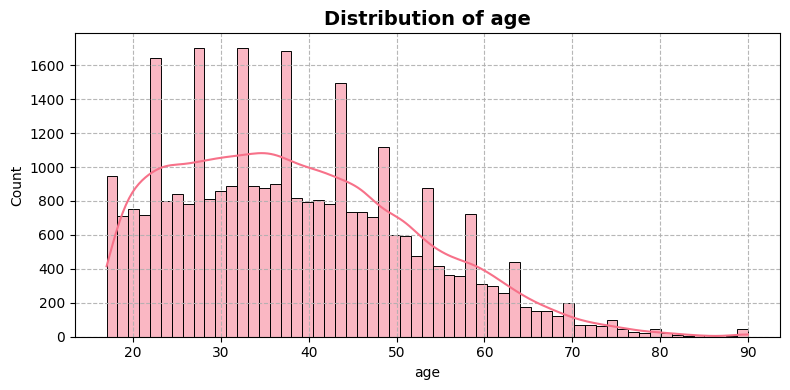

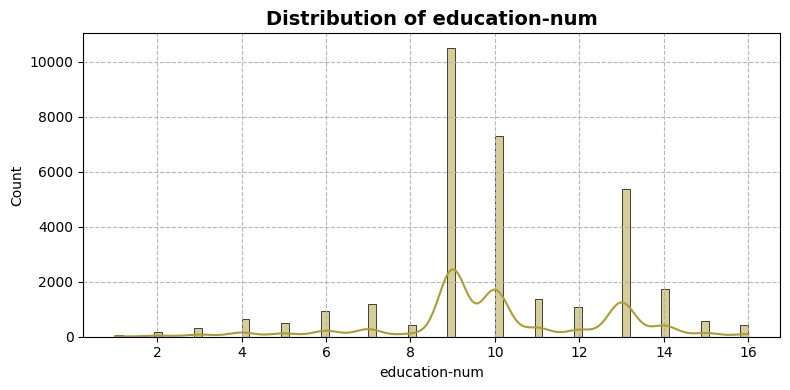

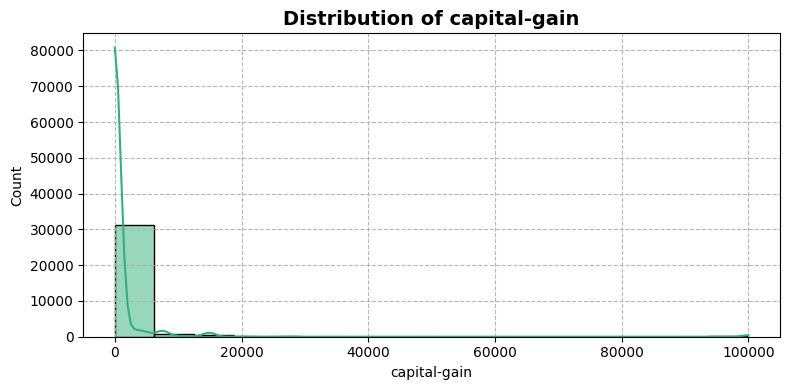

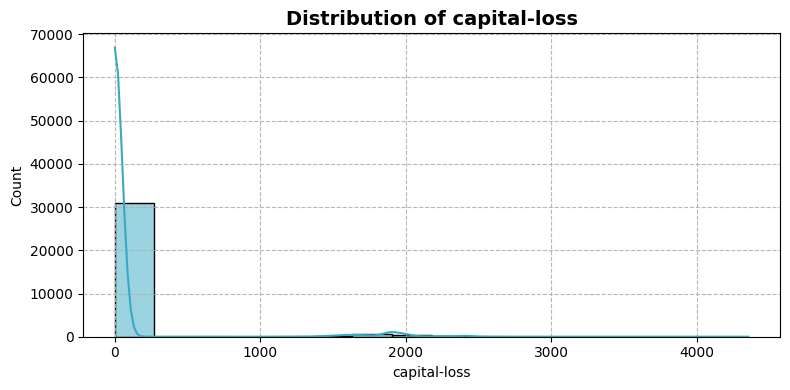

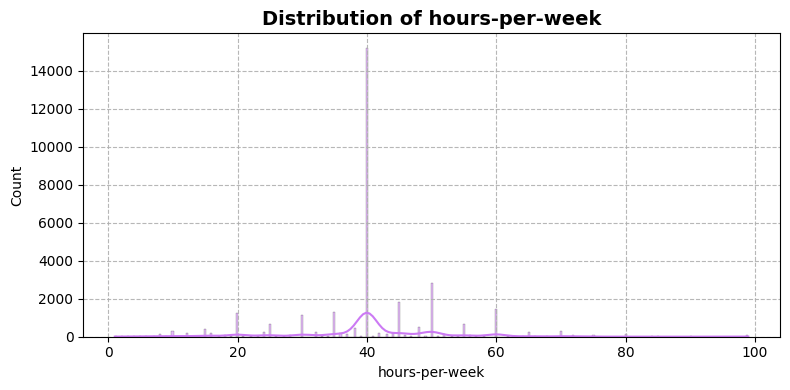

In [ ]:
palette = sns.color_palette("husl" , len(df.select_dtypes(include="number").columns))

for idx , col in enumerate(df.select_dtypes(include="number").columns):
  plt.figure(figsize=(8 , 4))
  sns.histplot(data=df , x=col , color=palette[idx] , edgecolor="black" , kde=True)
  plt.title(f"Distribution of {col}" , fontsize=14 , fontweight="bold")
  plt.grid(True , linestyle='--' , alpha=0.9)
  plt.tight_layout()
  plt.show()

In [4]:
# 1. Create a completely separate copy for Exploratory Data Analysis (EDA)
df_eda = df.copy()

# 2. Convert the target variable (income_bracket) into binary values (0 and 1)
df_eda["income"] = (
    df_eda["income"]
    .astype(str)
    .str.rstrip(".")
    .map({"<=50K": 0, ">50K": 1})
)

# 3. Encode categorical (Object) columns into numeric values while preserving NaN
cat_columns = df_eda.select_dtypes(include=["object"]).columns

for col in cat_columns:
    cat_series = df_eda[col].astype("category")
    # Replace -1 (automatically assigned by pandas to NaN) with np.nan to avoid distorting correlation calculations
    df_eda[col] = cat_series.cat.codes.replace(-1, np.nan)

# 4. Ensure that all columns are fully numeric
print("EDA Data Shape:", df_eda.shape)
print("\nColumn Data Types After Encoding:")
print(df_eda.dtypes)
df_eda.head()

EDA Data Shape: (32561, 13)

Column Data Types After Encoding:
age                 int64
workclass         float64
education-num       int64
marital-status       int8
occupation        float64
relationship         int8
race                 int8
sex                  int8
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country    float64
income              int64
dtype: object


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,6.0,13,4,0.0,1,4,1,2174,0,40,38.0,0
1,50,5.0,13,2,3.0,0,4,1,0,0,13,38.0,0
2,38,3.0,9,0,5.0,1,4,1,0,0,40,38.0,0
3,53,3.0,7,2,5.0,0,2,1,0,0,40,38.0,0
4,28,3.0,13,2,9.0,5,2,0,0,0,40,4.0,0


/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


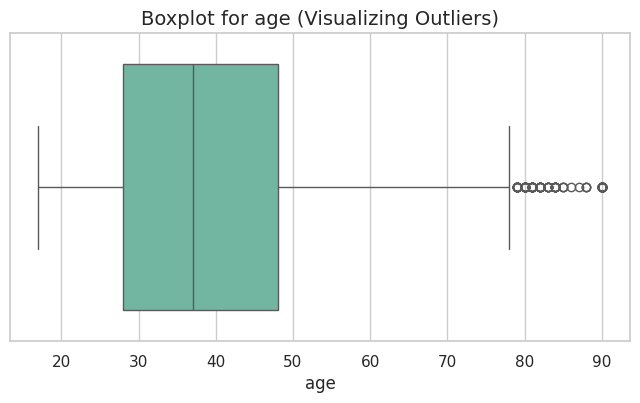

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


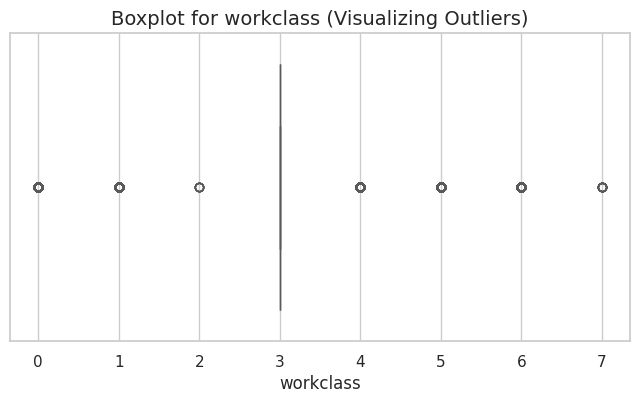

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


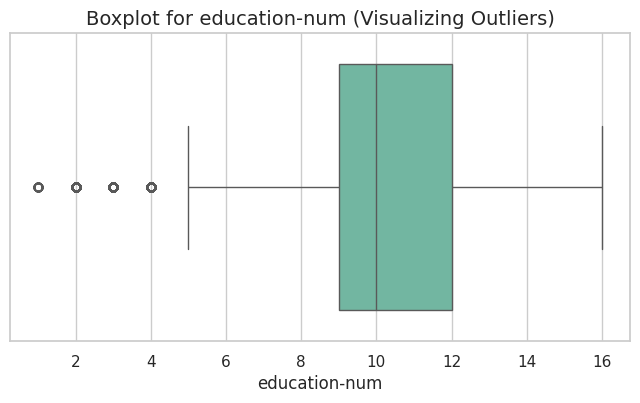

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


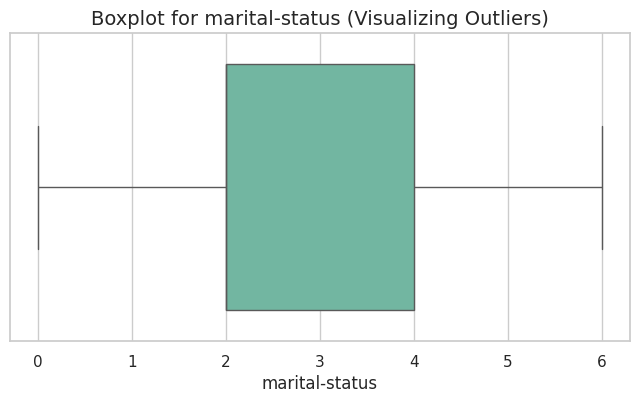

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


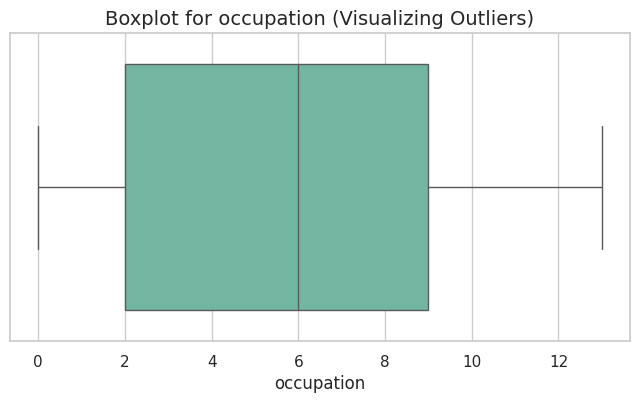

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


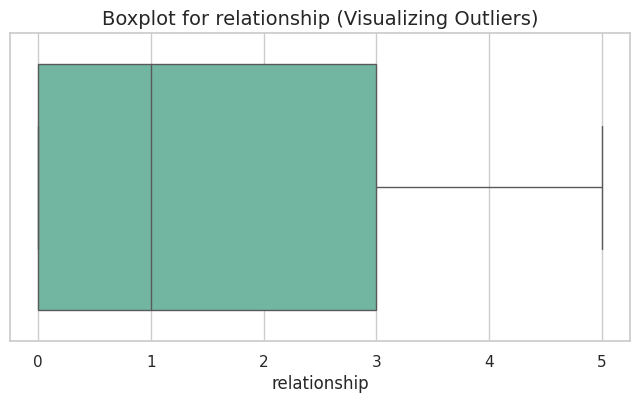

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


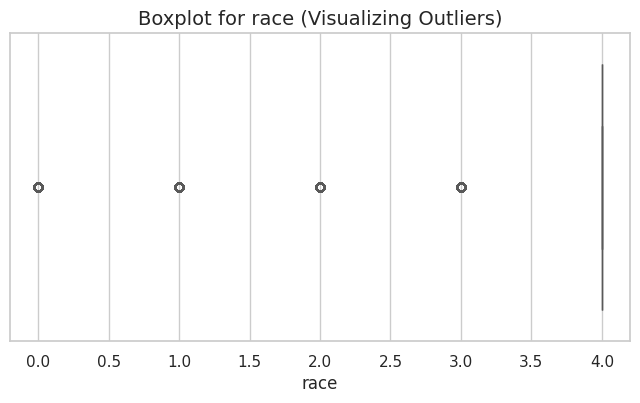

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


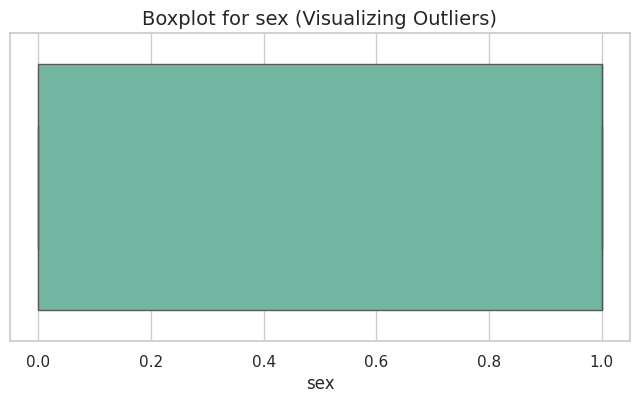

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


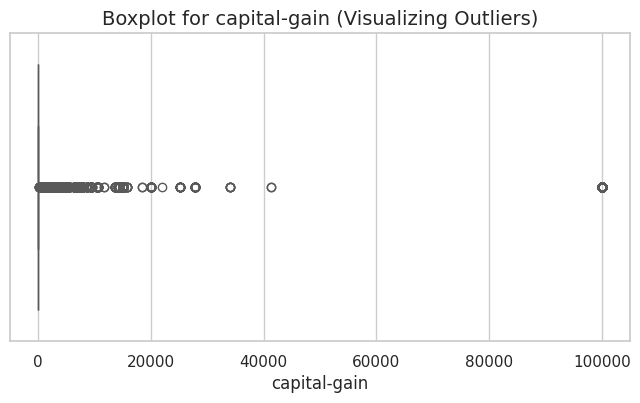

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


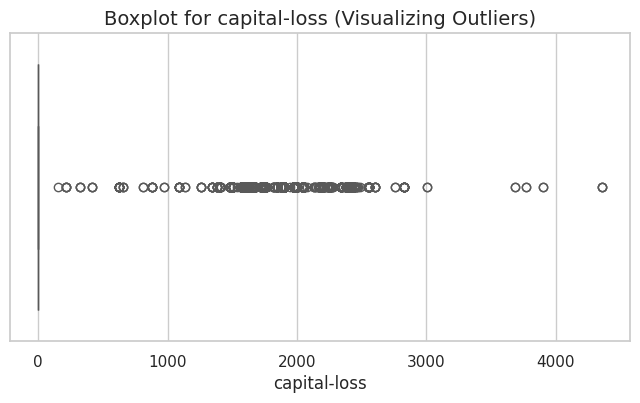

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


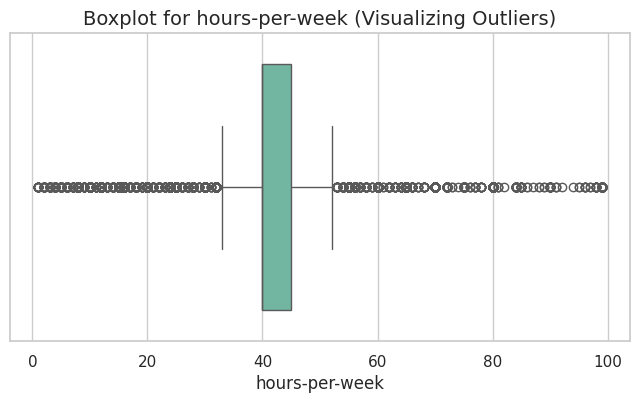

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


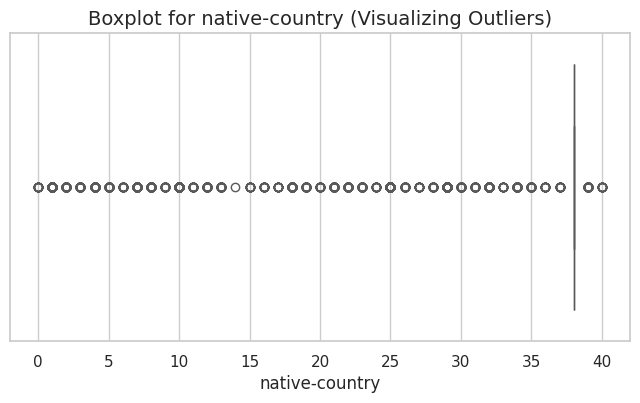

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


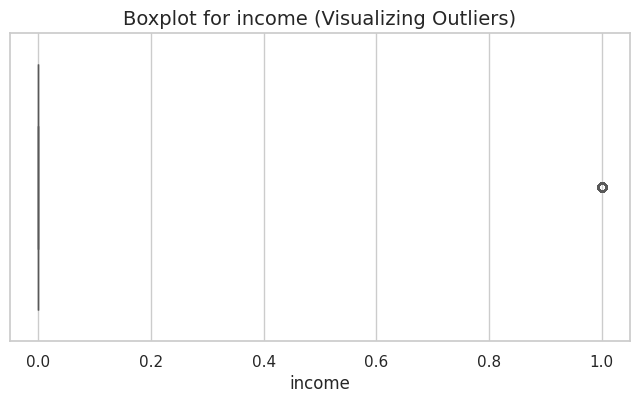

In [ ]:
for col in df_eda.columns:
  plt.figure(figsize=(8 , 4))
  sns.boxplot(data=df_eda , x=col , palette="Set2")
  plt.title(f"Boxplot for {col} (Visualizing Outliers)" , fontsize=14)
  plt.show()

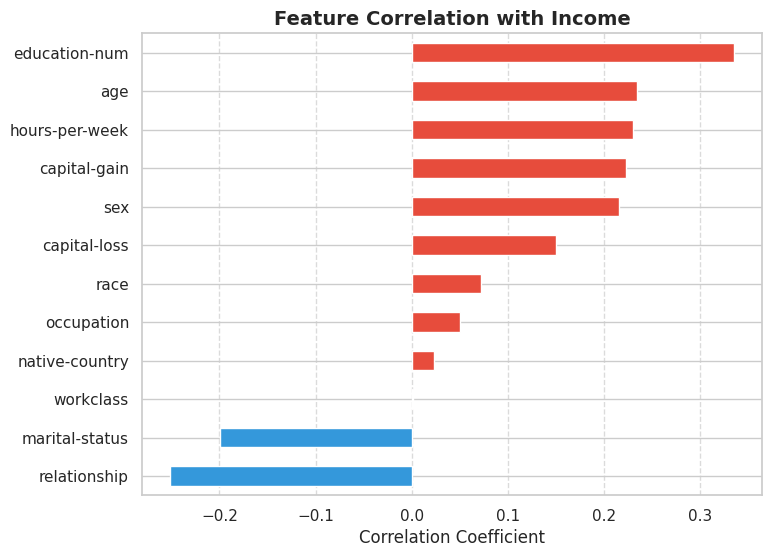

In [ ]:
income_corr = df_eda.corr()['income'].drop('income').sort_values(ascending=True)

plt.figure(figsize=(8, 6))
income_corr.plot(kind='barh', color=income_corr.map(lambda x: '#e74c3c' if x > 0 else '#3498db'))
plt.title("Feature Correlation with Income", fontsize=14, fontweight='bold')
plt.xlabel("Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Exploratory Data Analysis: Findings and Feature Engineering Decisions

---

### 1. Data Cleaning and Feature Selection

- Converted missing values represented by `?` into `np.nan` across the dataset.
- Removed `education` because it represents the same educational attainment information as `education_num`, which provides a numerical representation of education level.
- Removed `fnlwgt` because it represents the final sampling weight used in the census dataset rather than a direct individual attribute.

### 2. Missing Values Analysis

Missing values were found in three categorical features:

| Feature | Missing Values | Percentage |
|:---|---:|---:|
| `occupation` | 1,843 | 5.66% |
| `workclass` | 1,836 | 5.64% |
| `native-country` | 583 | 1.79% |

The numerical features contained no missing values.

**Decision:** Missing categorical values will be imputed using the most frequent category calculated from the training set. Imputation will be performed after the train-test split to prevent data leakage.

### 3. Class Distribution

The target variable contains two classes:

| Income Class | Number of Samples | Percentage |
|:---|---:|---:|
| `<=50K` | 24,720 | 75.92% |
| `>50K` | 7,841 | 24.08% |

The ratio between the majority and minority classes is approximately 3.15:1.

**Modeling decisions:**

- Use ROC-AUC, PR-AUC, and F1-Score to evaluate model performance rather than relying on accuracy alone.
- Use stratified splitting and `StratifiedKFold` to preserve class proportions.
- Evaluate class weighting in boosting models where supported, using validation results to select appropriate values.

### 4. Numerical Distributions and Outliers

- **Capital Features:** `capital_gain` contains approximately 91.6% zero values, while `capital_loss` contains approximately 95.3%. Both features are strongly right-skewed, with observed values reaching 99,999.
- **Working Hours:** `hours_per_week` has a mean of 40.43 hours and a standard deviation of 12.35. Most observations are concentrated around a standard working week, with variation in part-time and longer working hours.
- **Age:** Ages range from 17 to 90 years, with a median of 37 years and a moderately right-skewed distribution.

**Decision:** Outliers will not be removed solely because they fall outside conventional statistical limits. Tree-based models will be evaluated using the original numerical values, while additional features will capture relevant information such as capital activity.

### 5. Correlation and Categorical Patterns

#### Numerical Features

The strongest reported linear correlations with the income target were:

| Feature | Correlation with Income |
|:---|---:|
| `education_num` | +0.34 |
| `age` | +0.23 |
| `hours_per_week` | +0.23 |
| `capital_gain` | +0.22 |

These correlations provide an initial view of the relationship between numerical features and income. They do not capture all nonlinear relationships or interactions between variables.

#### Categorical Features

- **`marital_status`:** The `Married-civ-spouse` category has a higher proportion of individuals earning above $50K than several unmarried categories.
- **`native_country`:** The feature contains 41 distinct countries, with `United-States` accounting for approximately 89.58% of observations.

### 6. Feature Engineering Plan

#### Capital Features

- `capital_net` = `capital_gain - capital_loss`
- `has_capital_gain` = `1` if `capital_gain > 0`, otherwise `0`.
- `has_capital_loss` = `1` if `capital_loss > 0`, otherwise `0`.

#### Categorical Features

- **`native_country`:** Create a binary feature distinguishing `United-States` from other recorded countries.
- **`marital_status`:** Group categories into broader married and unmarried groups using a consistent mapping.

These transformations are intended to simplify selected features while preserving information relevant to income prediction.

---

### Next Phase: Data Splitting and Model Pipelines

The dataset will be divided into an 80% training set and a 20% hold-out test set using stratified sampling. Separate preprocessing pipelines will then be prepared for XGBoost, LightGBM, and CatBoost, with preprocessing parameters fitted using training data only.

In [5]:
from sklearn.model_selection import train_test_split

# 1. Encode target variable 'income' to binary (0 and 1)
df['income'] = df['income'].astype(str).str.rstrip('.').map({'<=50K': 0, '>50K': 1})

# 2. Separate features (X) and target (y)
X = df.drop('income', axis=1)
y = df['income']

# 3. Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Reset index for clean indexing
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")
print(f"Train Class Distribution:\n{y_train.value_counts(normalize=True).round(4)}")

X_train shape: (26048, 12) | y_train shape: (26048,)
X_test shape:  (6513, 12)  | y_test shape:  (6513,)
Train Class Distribution:
income
0    0.7592
1    0.2408
Name: proportion, dtype: float64


In [6]:
# Identify categorical columns containing missing values
missing_cat_cols = ['workclass', 'occupation', 'native-country']

# Compute the mode for each column strictly from X_train to prevent data leakage
train_modes = {col: X_train[col].mode()[0] for col in missing_cat_cols}
print("Computed Modes from X_train:")
for col, mode_val in train_modes.items():
    print(f"  {col}: {mode_val}")

# Impute missing values in both X_train and X_test using the train modes
for col, mode_val in train_modes.items():
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col] = X_test[col].fillna(mode_val)

# Verify no missing values remain
print(f"\nRemaining missing values in X_train: {X_train.isnull().sum().sum()}")
print(f"Remaining missing values in X_test:  {X_test.isnull().sum().sum()}")

Computed Modes from X_train:
  workclass: Private
  occupation: Prof-specialty
  native-country: United-States

Remaining missing values in X_train: 0
Remaining missing values in X_test:  0


In [7]:
# Define a helper function to apply feature engineering consistently
def engineer_features(data):
    df_feat = data.copy()

    # 1. Capital Net feature
    df_feat['capital_net'] = df_feat['capital-gain'] - df_feat['capital-loss']

    # 2. Binary indicators for capital investments
    df_feat['has_capital_gain'] = (df_feat['capital-gain'] > 0).astype(int)
    df_feat['has_capital_loss'] = (df_feat['capital-loss'] > 0).astype(int)

    # 3. Consolidate high-cardinality native-country (United-States vs Other)
    df_feat['is_native_us'] = (df_feat['native-country'] == 'United-States').astype(int)

    # 4. Consolidate marital-status into Married vs Unmarried
    married_categories = ['Married-civ-spouse', 'Married-AF-spouse']
    df_feat['is_married'] = df_feat['marital-status'].isin(married_categories).astype(int)

    # 5. Working hours indicator (Overtime vs Standard/Part-time)
    df_feat['is_overtime'] = (df_feat['hours-per-week'] > 40).astype(int)

    return df_feat

# Apply feature engineering to train and test sets
X_train = engineer_features(X_train)
X_test = engineer_features(X_test)

print("Engineered Features Added Successfully.")
print(f"Updated X_train shape: {X_train.shape}")
print(f"Updated X_test shape:  {X_test.shape}")
X_train[['capital_net', 'has_capital_gain', 'is_native_us', 'is_married', 'is_overtime']].head()

Engineered Features Added Successfully.
Updated X_train shape: (26048, 18)
Updated X_test shape:  (6513, 18)


,capital_net,has_capital_gain,is_native_us,is_married,is_overtime
0,0,0,1,1,1
1,0,0,1,0,1
2,0,0,1,0,0
3,6849,1,1,0,0
4,0,0,1,0,0


In [8]:
# Skewed features to transform using log1p (strictly non-negative)
skewed_cols = ['capital-gain', 'capital-loss']

for col in skewed_cols:
    # Create log-transformed columns (log1p = log(x + 1))
    X_train[f'{col}_log'] = np.log1p(X_train[col])
    X_test[f'{col}_log'] = np.log1p(X_test[col])

print("Log Transformation Applied to Skewed Continuous Features.")
print(f"Final X_train shape: {X_train.shape}")
print(f"Final X_test shape:  {X_test.shape}")
X_train[[f'{col}_log' for col in skewed_cols]].describe().T[['min', 'mean', '50%', 'max']].round(2)

Log Transformation Applied to Skewed Continuous Features.
Final X_train shape: (26048, 20)
Final X_test shape:  (6513, 20)


,min,mean,50%,max
capital-gain_log,0.0,0.73,0.0,11.51
capital-loss_log,0.0,0.35,0.0,8.38


In [9]:
# Verify dataset consistency and check data types
print("=== X_train Info Summary ===")
print(f"Total Features: {X_train.shape[1]}")
print(f"Numerical Features: {len(X_train.select_dtypes(include=['number']).columns)}")
print(f"Categorical Features: {len(X_train.select_dtypes(include=['object', 'category']).columns)}")
print(f"Categorical Columns List: {X_train.select_dtypes(include=['object', 'category']).columns.tolist()}")

# Ensure zero NaNs across train and test sets
assert X_train.isnull().sum().sum() == 0, "Warning: Null values detected in X_train!"
assert X_test.isnull().sum().sum() == 0, "Warning: Null values detected in X_test!"
print("\nIntegrity Check Passed: Zero missing values detected across both datasets.")

=== X_train Info Summary ===
Total Features: 20
Numerical Features: 13
Categorical Features: 7
Categorical Columns List: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Integrity Check Passed: Zero missing values detected across both datasets.


In [10]:
from sklearn.model_selection import StratifiedKFold

# 1. Clean feature names (replace '-' with '_' for LightGBM/XGBoost safety)
X_train.columns = X_train.columns.str.replace('-', '_')
X_test.columns = X_test.columns.str.replace('-', '_')

# 2. Explicitly define categorical and numerical feature lists
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()

print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")
print(f"Numerical Features ({len(num_cols)}): {num_cols}")

# 3. Calculate scale_pos_weight for handling class imbalance in boosting models
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"\nCalculated scale_pos_weight: {scale_pos_weight:.2f}")

# 4. Initialize unified Stratified 5-Fold CV scheme
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Stratified 5-Fold Cross-Validation Strategy Initialized.")

Categorical Features (7): ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Numerical Features (13): ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_native_us', 'is_married', 'is_overtime', 'capital_gain_log', 'capital_loss_log']

Calculated scale_pos_weight: 3.15
Stratified 5-Fold Cross-Validation Strategy Initialized.


# Data Preprocessing and Feature Engineering Summary

---

### 1. Data Splitting and Leakage Prevention

- **Target Encoding:** Converted `income` into a binary variable (`0` for `<=50K` and `1` for `>50K`).
- **Stratified Split:** Split the dataset into 80% training data and 20% test data using `train_test_split`, with `stratify=y` and `random_state=42`.
- **Data Integrity:** Reset the indices of both partitions. Statistical parameters used in preprocessing were calculated from the training set and then applied to the test set where appropriate.

### 2. Missing Value Imputation

- Checked the categorical features `workclass`, `occupation`, and `native_country` for missing values.
- Filled missing values using the most frequent category calculated from `X_train`.
- Applied the same imputation values to `X_train` and `X_test`.
- Verified that no missing values remained after imputation.

### 3. Feature Engineering

The following features were created for both the training and test sets:

- **Net Capital (`capital_net`):** Calculated as `capital_gain - capital_loss` to represent the difference between capital gains and losses.
- **Capital Activity Indicators (`has_capital_gain`, `has_capital_loss`):** Binary features indicating whether capital gains or losses are greater than zero.
- **Marital Status (`is_married`):** Combined the relevant married categories into a binary indicator distinguishing married from unmarried individuals.
- **Geographic Indicator (`is_native_us`):** Created a binary feature distinguishing individuals whose recorded native country is the United States from those with another recorded country.
- **Overtime Indicator (`is_overtime`):** Set to `1` when `hours_per_week > 40` and `0` otherwise.

### 4. Log Transformations

Applied `np.log1p` to the capital gain and capital loss features to reduce the effect of their right-skewed distributions.

- `capital_gain_log = np.log1p(capital_gain)`
- `capital_loss_log = np.log1p(capital_loss)`

These transformations were applied to non-negative features. The original capital values were retained for use in other engineered features, including `capital_net`.

### 5. Feature Preparation and Validation

- **Feature Names:** Replaced hyphens with underscores in feature names to maintain consistent naming across preprocessing and modeling pipelines.
- **Feature Groups:** Organized features into `cat_cols` for categorical variables and `num_cols` for numerical variables and binary indicators.
- **Class Weighting:** Calculated the positive-to-negative class ratio from `y_train`, approximately 3.15:1, for use in the boosting models where applicable.
- **Cross-Validation:** Configured `StratifiedKFold` with five splits, `shuffle=True`, and `random_state=42`. The same fold configuration was used across model optimization and evaluation workflows, including the generation of out-of-fold predictions for stacking.

# Modeling Strategy: Benchmarking and Hyperparameter Optimization

---

### 1. Modeling Strategy

The modeling phase is divided into two tracks to compare ensemble methods and gradient boosting frameworks under consistent evaluation conditions.

Each architecture uses a dedicated pipeline with a `ColumnTransformer` where needed. Optuna is used for hyperparameter optimization, and `StratifiedKFold` with five folds is used for cross-validation.

Preprocessing steps are fitted within the training folds to prevent data leakage during model evaluation.

---

### 2. Track A: Ensemble Models

Track A compares three ensemble approaches: Soft Voting, Blending, and Stacking.

#### 1. Soft Voting Classifier

- **Base Estimators:** Different model types, such as Logistic Regression, Random Forest or Gradient Boosting, K-Nearest Neighbors, and Support Vector Classifier.
- **Mechanism:** Combines predicted class probabilities from multiple models using an average or weighted average.
- **Optimization:** Tunes the base model parameters and, where applicable, the voting weights.

#### 2. Blending

- **Base Estimators:** Random Forest, K-Nearest Neighbors, and Logistic Regression.
- **Meta-Learner:** Logistic Regression.
- **Mechanism:** Trains the base models on one subset of the training data and trains the meta-learner on predictions generated from a separate hold-out subset.
- **Evaluation Focus:** Examines how reserving part of the training data for the meta-learner affects the performance of the ensemble.

#### 3. Stacking Classifier

- **Base Estimators:** Random Forest, K-Nearest Neighbors, and Logistic Regression.
- **Meta-Learner:** Regularized Logistic Regression.
- **Mechanism:** Uses out-of-fold (OOF) predictions generated through cross-validation to train the meta-learner.
- **Evaluation Focus:** Compares the performance of cross-validation-based stacking with blending, which uses a separate subset for meta-model training.

---

### 3. Track B: Gradient Boosting Models

Track B compares XGBoost, LightGBM, and CatBoost using the same validation strategy.

#### 1. XGBoost

- **Preprocessing:** Uses `ColumnTransformer` and One-Hot Encoding for categorical features, with numerical features passed through the preprocessing pipeline as configured.
- **Hyperparameter Tuning:** Focuses on `gamma`, `reg_lambda`, `learning_rate`, `max_depth`, and `scale_pos_weight`.

#### 2. LightGBM

- **Preprocessing:** Uses supported categorical feature representations to enable native categorical splitting where configured.
- **Hyperparameter Tuning:** Focuses on `num_leaves`, `min_child_samples`, learning rate, and tree complexity controls. Sampling parameters are also tuned where applicable.

#### 3. CatBoost

- **Preprocessing:** Passes categorical features through the pipeline in a format supported by CatBoost and specifies them using `cat_features`.
- **Hyperparameter Tuning:** Focuses on `depth`, `l2_leaf_reg`, `random_strength`, and parameters controlling categorical feature processing.

#### Track B Evaluation Criteria

The three frameworks are compared based on:

- Total optimization time across Optuna trials.
- Memory consumption and model artifact size, where measured.
- Predictive performance on the validation data.
- Training behavior with categorical features, including high-cardinality variables.

---

### 4. Final Evaluation and Model Comparison

After hyperparameter optimization, the six selected architectures are evaluated on the 20% hold-out test set (`X_test`, `y_test`).

The evaluation includes the following metrics:

- **Classification Metrics:** Accuracy, Precision, Recall, and F1-Score.
- **Ranking Metrics:** ROC-AUC and Precision-Recall AUC (PR-AUC).
- **Inference Performance:** Prediction latency per sample, measured in milliseconds.
- **Generalization:** The difference between cross-validation performance and hold-out test performance.

The final comparison is used to select a model based on predictive performance, inference speed, and computational requirements.

In [12]:
!pip install optuna -q

import optuna
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# ---------------------------------------------------------
# 1. Feature Preprocessing Specifications
# ---------------------------------------------------------
cat_features = cat_cols.copy()
num_features = num_cols.copy()

# Preprocessor for Linear & Distance models (Logistic Regression & KNN)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Preprocessor for Tree-based model (Gradient Boosting Machine)
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# ---------------------------------------------------------
# 2. Optuna Objective Function for Voting Classifier (F1-Score)
# ---------------------------------------------------------


def objective_voting(trial):
  # --- A. Logistic Regression Hyperparameters ---
  lr_solver_type = trial.suggest_categorical(
      "lr_solver_type", ["lbfgs", "liblinear", "saga"]
  )
  lr_C = trial.suggest_float("lr_C", 1e-2, 1e2, log=True)
  lr_class_weight = trial.suggest_categorical(
      "lr_class_weight", [None, "balanced"]
  )

  if lr_solver_type == "liblinear":
    lr_penalty = trial.suggest_categorical("lr_penalty_liblinear", ["l1", "l2"])
    clf_lr = LogisticRegression(
        solver="liblinear",
        penalty=lr_penalty,
        C=lr_C,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )
  elif lr_solver_type == "lbfgs":
    clf_lr = LogisticRegression(
        solver="lbfgs",
        penalty="l2",
        C=lr_C,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )
  else:  # saga
    lr_penalty = trial.suggest_categorical(
        "lr_penalty_saga", ["l1", "l2", "elasticnet"]
    )
    lr_l1_ratio = (
        trial.suggest_float("lr_l1_ratio", 0.1, 0.9)
        if lr_penalty == "elasticnet"
        else None
    )
    clf_lr = LogisticRegression(
        solver="saga",
        penalty=lr_penalty,
        C=lr_C,
        l1_ratio=lr_l1_ratio,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )

  # --- B. Gradient Boosting Classifier Hyperparameters ---
  gbm_loss = trial.suggest_categorical("gbm_loss", ["log_loss", "exponential"])
  gbm_learning_rate = trial.suggest_float(
      "gbm_learning_rate", 0.01, 0.2, log=True
  )
  gbm_n_estimators = trial.suggest_int("gbm_n_estimators", 100, 400, step=50)
  gbm_max_depth = trial.suggest_int("gbm_max_depth", 2, 5)
  gbm_subsample = trial.suggest_float("gbm_subsample", 0.7, 1.0)
  gbm_min_samples_split = trial.suggest_int("gbm_min_samples_split", 2, 10)
  gbm_min_samples_leaf = trial.suggest_int("gbm_min_samples_leaf", 1, 4)

  clf_gbm = GradientBoostingClassifier(
      loss=gbm_loss,
      learning_rate=gbm_learning_rate,
      n_estimators=gbm_n_estimators,
      max_depth=gbm_max_depth,
      subsample=gbm_subsample,
      min_samples_split=gbm_min_samples_split,
      min_samples_leaf=gbm_min_samples_leaf,
      n_iter_no_change=10,
      validation_fraction=0.1,
      random_state=42,
  )

  # --- C. K-Nearest Neighbors Hyperparameters ---
  knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 5, 21, step=2)
  knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
  knn_p = trial.suggest_categorical("knn_p", [1, 2])

  clf_knn = KNeighborsClassifier(
      n_neighbors=knn_n_neighbors,
      weights=knn_weights,
      p=knn_p,
      metric="minkowski",
      n_jobs=-1,
  )

  # --- D. Individual Pipelines Assembly ---
  pipe_lr = Pipeline([
      ("preprocessor", preprocessor_scaled),
      ("classifier", clf_lr),
  ])

  pipe_gbm = Pipeline([
      ("preprocessor", preprocessor_unscaled),
      ("classifier", clf_gbm),
  ])

  pipe_knn = Pipeline([
      ("preprocessor", preprocessor_scaled),
      ("classifier", clf_knn),
  ])

  # --- E. Ensemble Probability Voting Weights ---
  w_lr = trial.suggest_float("weight_lr", 0.5, 3.0)
  w_gbm = trial.suggest_float("weight_gbm", 1.0, 4.0)
  w_knn = trial.suggest_float("weight_knn", 0.2, 2.0)

  voting_clf = VotingClassifier(
      estimators=[("lr", pipe_lr), ("gbm", pipe_gbm), ("knn", pipe_knn)],
      voting="soft",
      weights=[w_lr, w_gbm, w_knn],
      n_jobs=-1,
  )

  # --- F. Cross-Validation Evaluation (F1-Score Optimization) ---
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  scores = cross_val_score(
      voting_clf, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1
  )

  return scores.mean()


# ---------------------------------------------------------
# 3. Execute Optuna Optimization Study
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_voting = optuna.create_study(
    direction="maximize", study_name="Voting_Classifier_F1_Tuning"
)

# Run 25 optimization trials
print("Starting Voting Classifier")
study_voting.optimize(objective_voting, n_trials=25, timeout=1200)

print("\n" + "=" * 50)
print("Voting Optimization Complete")
print(f"Best F1-Score: {study_voting.best_value:.5f}")
print("Best Parameters:")
for k, v in study_voting.best_params.items():
  print(f"  {k}: {v}")
print("=" * 50)

[I 2026-10-15 18:20:09,800] A new study created in memory with name: Voting_Classifier_F1_Tuning


Starting Voting Classifier


[I 2026-10-15 18:21:28,456] Trial 0 finished with value: 0.7068267018351926 and parameters: {'lr_solver_type': 'liblinear', 'lr_C': 0.05599002614168206, 'lr_class_weight': 'balanced', 'lr_penalty_liblinear': 'l1', 'gbm_loss': 'exponential', 'gbm_learning_rate': 0.029280041186550858, 'gbm_n_estimators': 400, 'gbm_max_depth': 3, 'gbm_subsample': 0.9066448342884212, 'gbm_min_samples_split': 4, 'gbm_min_samples_leaf': 4, 'knn_n_neighbors': 7, 'knn_weights': 'distance', 'knn_p': 2, 'weight_lr': 0.6694065013202819, 'weight_gbm': 3.0419002526034844, 'weight_knn': 1.4245266350903762}. Best is trial 0 with value: 0.7068267018351926.
[I 2026-10-15 18:22:31,958] Trial 1 finished with value: 0.6858891547495715 and parameters: {'lr_solver_type': 'liblinear', 'lr_C': 53.15128551891913, 'lr_class_weight': None, 'lr_penalty_liblinear': 'l1', 'gbm_loss': 'exponential', 'gbm_learning_rate': 0.0541921960278507, 'gbm_n_estimators': 100, 'gbm_max_depth': 2, 'gbm_subsample': 0.8148394170439576, 'gbm_min_sam


Voting Optimization Complete
Best F1-Score: 0.72070
Best Parameters:
  lr_solver_type: liblinear
  lr_C: 56.25027955073156
  lr_class_weight: balanced
  lr_penalty_liblinear: l2
  gbm_loss: exponential
  gbm_learning_rate: 0.037023331482513105
  gbm_n_estimators: 300
  gbm_max_depth: 5
  gbm_subsample: 0.9335290292158578
  gbm_min_samples_split: 8
  gbm_min_samples_leaf: 4
  knn_n_neighbors: 13
  knn_weights: distance
  knn_p: 1
  weight_lr: 2.30217068967148
  weight_gbm: 3.4031170133850166
  weight_knn: 1.6996326683386194


In [13]:
import numpy as np
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# ---------------------------------------------------------
# 1. Feature Preprocessing Specifications
# ---------------------------------------------------------
cat_features = cat_cols.copy()
num_features = num_cols.copy()

# Preprocessor with scaling (for Logistic Regression and KNN)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Preprocessor without scaling (for Random Forest)
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# ---------------------------------------------------------
# 2. Optuna Objective Function for Blending (Optimizing F1-Score)
# ---------------------------------------------------------


def objective_blending(trial):
  # Split X_train into Base Model training (80%) and Meta-Learner Blending set (20%)
  X_base, X_blend, y_base, y_blend = train_test_split(
      X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
  )

  # --- A. Logistic Regression (Base Model 1) Hyperparameters ---
  lr_C = trial.suggest_float("lr_C", 1e-2, 1e2, log=True)
  lr_penalty = trial.suggest_categorical("lr_penalty", ["l1", "l2"])
  clf_lr = LogisticRegression(
      solver="liblinear",
      penalty=lr_penalty,
      C=lr_C,
      class_weight="balanced",
      max_iter=1000,
      random_state=42,
  )

  pipe_lr = Pipeline(
      [("preprocessor", preprocessor_scaled), ("classifier", clf_lr)]
  )

  # --- B. Random Forest (Base Model 2) Hyperparameters ---
  rf_n_estimators = trial.suggest_int("rf_n_estimators", 100, 300, step=50)
  rf_max_depth = trial.suggest_int("rf_max_depth", 6, 20)
  rf_min_samples_split = trial.suggest_int("rf_min_samples_split", 2, 10)
  rf_min_samples_leaf = trial.suggest_int("rf_min_samples_leaf", 1, 4)
  rf_max_features = trial.suggest_categorical("rf_max_features", ["sqrt", 0.5])
  rf_class_weight = trial.suggest_categorical(
      "rf_class_weight", [None, "balanced", "balanced_subsample"]
  )

  clf_rf = RandomForestClassifier(
      n_estimators=rf_n_estimators,
      max_depth=rf_max_depth,
      min_samples_split=rf_min_samples_split,
      min_samples_leaf=rf_min_samples_leaf,
      max_features=rf_max_features,
      class_weight=rf_class_weight,
      bootstrap=True,
      random_state=42,
      n_jobs=-1,
  )

  pipe_rf = Pipeline(
      [("preprocessor", preprocessor_unscaled), ("classifier", clf_rf)]
  )

  # --- C. K-Nearest Neighbors (Base Model 3) Hyperparameters ---
  knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 5, 21, step=2)
  knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
  knn_p = trial.suggest_categorical("knn_p", [1, 2])

  clf_knn = KNeighborsClassifier(
      n_neighbors=knn_n_neighbors,
      weights=knn_weights,
      p=knn_p,
      metric="minkowski",
      n_jobs=-1,
  )

  pipe_knn = Pipeline(
      [("preprocessor", preprocessor_scaled), ("classifier", clf_knn)]
  )

  # --- D. Train Base Models on X_base ---
  pipe_lr.fit(X_base, y_base)
  pipe_rf.fit(X_base, y_base)
  pipe_knn.fit(X_base, y_base)

  # --- E. Generate Meta-Features on X_blend ---
  meta_train = np.column_stack([
      pipe_lr.predict_proba(X_blend)[:, 1],
      pipe_rf.predict_proba(X_blend)[:, 1],
      pipe_knn.predict_proba(X_blend)[:, 1],
  ])

  # --- F. Meta-Learner (Logistic Regression) Hyperparameters & Training ---
  meta_C = trial.suggest_float("meta_C", 1e-2, 1e2, log=True)
  meta_class_weight = trial.suggest_categorical(
      "meta_class_weight", [None, "balanced"]
  )

  meta_learner = LogisticRegression(
      C=meta_C,
      solver="lbfgs",
      penalty="l2",
      class_weight=meta_class_weight,
      max_iter=1000,
      random_state=42,
  )

  # Evaluate Meta-Learner using 5-Fold Stratified CV on the Blend Set using F1-Score
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  fold_scores = []

  for train_idx, val_idx in cv.split(meta_train, y_blend):
    X_m_tr, X_m_val = meta_train[train_idx], meta_train[val_idx]
    y_m_tr, y_m_val = y_blend.iloc[train_idx], y_blend.iloc[val_idx]

    meta_learner.fit(X_m_tr, y_m_tr)
    preds_binary = meta_learner.predict(X_m_val)
    fold_scores.append(f1_score(y_m_val, preds_binary, pos_label=1))

  return np.mean(fold_scores)


# ---------------------------------------------------------
# 3. Execute Optuna Optimization Study for Blending
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_blending = optuna.create_study(
    direction="maximize", study_name="Blending_F1_Tuning"
)

# Run 25 optimization trials
print("Starting Blending Ensemble")
study_blending.optimize(objective_blending, n_trials=25, timeout=1200)

print("\n" + "=" * 50)
print("Blending Optimization Complete")
print(f"Best Blending F1-Score: {study_blending.best_value:.5f}")
print("Best Parameters:")
for k, v in study_blending.best_params.items():
  print(f"  {k}: {v}")
print("=" * 50)

[I 2026-10-15 18:40:28,110] A new study created in memory with name: Blending_F1_Tuning


Starting Blending Ensemble


[I 2026-10-15 18:40:58,438] Trial 0 finished with value: 0.7077710835106018 and parameters: {'lr_C': 1.166980539462451, 'lr_penalty': 'l2', 'rf_n_estimators': 300, 'rf_max_depth': 13, 'rf_min_samples_split': 6, 'rf_min_samples_leaf': 2, 'rf_max_features': 'sqrt', 'rf_class_weight': 'balanced', 'knn_n_neighbors': 5, 'knn_weights': 'uniform', 'knn_p': 2, 'meta_C': 15.391689182978814, 'meta_class_weight': None}. Best is trial 0 with value: 0.7077710835106018.
[I 2026-10-15 18:41:19,503] Trial 1 finished with value: 0.7044331500471758 and parameters: {'lr_C': 0.029655432821043565, 'lr_penalty': 'l2', 'rf_n_estimators': 150, 'rf_max_depth': 16, 'rf_min_samples_split': 2, 'rf_min_samples_leaf': 3, 'rf_max_features': 'sqrt', 'rf_class_weight': None, 'knn_n_neighbors': 7, 'knn_weights': 'distance', 'knn_p': 1, 'meta_C': 48.27298295641427, 'meta_class_weight': 'balanced'}. Best is trial 0 with value: 0.7077710835106018.
[I 2026-10-15 18:41:35,235] Trial 2 finished with value: 0.6915264159726917


Blending Optimization Complete
Best Blending F1-Score: 0.71155
Best Parameters:
  lr_C: 72.96367740471047
  lr_penalty: l2
  rf_n_estimators: 200
  rf_max_depth: 10
  rf_min_samples_split: 6
  rf_min_samples_leaf: 3
  rf_max_features: sqrt
  rf_class_weight: balanced
  knn_n_neighbors: 7
  knn_weights: uniform
  knn_p: 2
  meta_C: 29.40186461224425
  meta_class_weight: None


In [14]:
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score

# ---------------------------------------------------------
# 1. Preprocessors (Scaled vs Unscaled)
# ---------------------------------------------------------
cat_features = cat_cols.copy()
num_features = num_cols.copy()

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

# ---------------------------------------------------------
# 2. Fast Hold-out Split for Evaluation (Eliminates Nested CV)
# ---------------------------------------------------------
# 80% to train Stacking (with internal OOF), 20% to instantly evaluate each trial
X_stk_train, X_stk_val, y_stk_train, y_stk_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# ---------------------------------------------------------
# 3. Optimized Fast Objective Function
# ---------------------------------------------------------
def objective_stacking_fast(trial):

    # --- A. Logistic Regression ---
    lr_C = trial.suggest_float('lr_C', 0.05, 20.0, log=True)
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(solver='liblinear', C=lr_C, class_weight='balanced', random_state=42))
    ])

    # --- B. Fast Random Forest (Capped estimators for high speed) ---
    rf_n_estimators = trial.suggest_int('rf_n_estimators', 60, 120, step=20)
    rf_max_depth = trial.suggest_int('rf_max_depth', 8, 16)
    pipe_rf = Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            max_features='sqrt',
            class_weight='balanced',
            random_state=42,
            n_jobs=2
        ))
    ])

    # --- C. Fast KNN ---
    knn_n_neighbors = trial.suggest_int('knn_n_neighbors', 7, 19, step=4)
    pipe_knn = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', KNeighborsClassifier(n_neighbors=knn_n_neighbors, weights='distance', n_jobs=2))
    ])

    # --- D. Meta-Learner (Logistic Regression) ---
    meta_C = trial.suggest_float('meta_C', 0.01, 10.0, log=True)
    meta_learner = LogisticRegression(C=meta_C, class_weight='balanced', max_iter=500, random_state=42)

    # --- E. Stacking Classifier with 3-Fold Internal CV ---
    # 3 Folds generate great OOF predictions at twice the speed of 5 folds
    cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    stacking_clf = StackingClassifier(
        estimators=[
            ('lr', pipe_lr),
            ('rf', pipe_rf),
            ('knn', pipe_knn)
        ],
        final_estimator=meta_learner,
        cv=cv_inner,
        stack_method='predict_proba',
        n_jobs=2
    )

    # Fit on training portion (calculates OOF internally and fits meta-learner)
    stacking_clf.fit(X_stk_train, y_stk_train)

    # Instant prediction on validation portion (takes ~2 seconds)
    preds = stacking_clf.predict(X_stk_val)

    return f1_score(y_stk_val, preds, pos_label=1)

# ---------------------------------------------------------
# 4. Run Accelerated Optimization
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_stacking = optuna.create_study(direction='maximize', study_name='Fast_Stacking_F1')

print("Starting Fast Stacking")
study_stacking.optimize(objective_stacking_fast, n_trials=15, timeout=900)

print("\n" + "="*50)
print("Stacking Optimization Complete")
print(f"Best Stacking F1-Score: {study_stacking.best_value:.5f}")
print("Best Parameters:")
for k, v in study_stacking.best_params.items():
    print(f"  {k}: {v}")
print("="*50)

[I 2026-10-15 18:47:24,588] A new study created in memory with name: Fast_Stacking_F1


Starting Fast Stacking


[I 2026-10-15 18:48:10,888] Trial 0 finished with value: 0.6895414054767404 and parameters: {'lr_C': 0.6570755462705048, 'rf_n_estimators': 80, 'rf_max_depth': 9, 'knn_n_neighbors': 7, 'meta_C': 6.791232257825718}. Best is trial 0 with value: 0.6895414054767404.
[I 2026-10-15 18:48:35,186] Trial 1 finished with value: 0.6955945677376615 and parameters: {'lr_C': 1.648253830236301, 'rf_n_estimators': 60, 'rf_max_depth': 9, 'knn_n_neighbors': 11, 'meta_C': 0.4334231205892988}. Best is trial 1 with value: 0.6955945677376615.
[I 2026-10-15 18:49:10,735] Trial 2 finished with value: 0.7010652463382158 and parameters: {'lr_C': 0.43353013764368203, 'rf_n_estimators': 120, 'rf_max_depth': 16, 'knn_n_neighbors': 15, 'meta_C': 0.13566502106775213}. Best is trial 2 with value: 0.7010652463382158.
[I 2026-10-15 18:49:36,878] Trial 3 finished with value: 0.6968894771674388 and parameters: {'lr_C': 15.65901603573308, 'rf_n_estimators': 80, 'rf_max_depth': 9, 'knn_n_neighbors': 11, 'meta_C': 2.3419047


Stacking Optimization Complete
Best Stacking F1-Score: 0.70288
Best Parameters:
  lr_C: 12.570303367511732
  rf_n_estimators: 80
  rf_max_depth: 14
  knn_n_neighbors: 19
  meta_C: 0.5908110897662446


# Comparative Analysis of Ensemble Architectures: Voting, Blending, and Stacking

---

### 1. Motivation: Why Ensemble Learning?
The fundamental premise of ensemble learning is that combining predictions from multiple distinct hypothesis spaces reduces both variance and bias, yielding a decision boundary that generalizes better than any individual estimator.

To maximize ensemble efficiency, base models must exhibit high **algorithmic diversity**:
- **Linear Models (Logistic Regression)**: Capture broad, global linear boundaries.
- **Tree-Based / Bagging & Boosting (Random Forest, GBM)**: Capture non-linear feature interactions and high-order threshold splits.
- **Distance-Based Models (K-Nearest Neighbors)**: Capture localized manifold geometry and local instance clustering.

---

### 2. Implementation Methodology of Each Architecture

#### A. Soft Voting Classifier
- **Base Estimators**: Logistic Regression, Gradient Boosting Classifier, and K-Nearest Neighbors.
- **Preprocessing Pipelines**:
  - Independent pipelines with `RobustScaler` and `OneHotEncoder` for Logistic Regression and KNN.
  - Scale-invariant pipeline (`passthrough` for numericals and `OneHotEncoder` for categoricals) for Gradient Boosting.
- **Aggregation Mechanism**:
  - Soft voting computes a weighted average of predicted class probabilities across all estimators:
    $$P(y=1\vert{}X) = \frac{\sum w_i P_i(y=1\vert{}X)}{\sum w_i}$$
  - Optuna optimizes the internal hyperparameters of all three estimators concurrently with the voting weights ($w_{LR}, w_{GBM}, w_{KNN}$) to maximize the F1-score via 5-fold Stratified Cross-Validation.

#### B. Blending Ensemble
- **Base Estimators**: Logistic Regression, Random Forest, and K-Nearest Neighbors.
- **Meta-Learner**: L2-regularized Logistic Regression (`solver='lbfgs'`).
- **Data Partitioning & Workflow**:
  - Training data (`X_train`) is explicitly split into an 80% Base Training Set (`X_base`) and a 20% Holdout/Blend Set (`X_blend`).
  - Base pipelines are fitted exclusively on `X_base`.
  - Fitted base pipelines predict class probabilities on `X_blend`, forming a 3-column meta-feature matrix $[P_{LR}, P_{RF}, P_{KNN}]$.
  - The meta-learner is trained on this meta-feature matrix to predict the true labels of `X_blend`.
- **Optimization**: Optuna tunes base model hyperparameters, meta-learner regularization parameter `C`, and class weights on the blend validation folds.

#### C. Stacking Classifier (Out-Of-Fold Meta-Learner)
- **Base Estimators**: Identical combination to Blending (Logistic Regression, Random Forest, K-Nearest Neighbors).
- **Meta-Learner**: Regularized Logistic Regression (`final_estimator`).
- **Out-of-Fold (OOF) Workflow**:
  - Utilizes Scikit-Learn's `StackingClassifier` with an internal 5-fold Stratified Cross-Validation scheme (`cv_inner`).
  - Base models generate Out-Of-Fold predictions across all training folds, constructing the meta-feature matrix across 100% of `X_train` without data leakage.
  - The meta-learner is fitted on the full OOF prediction matrix.
  - `stack_method='auto'` is enforced to feed predicted class probabilities into the meta-estimator.
- **Optimization**: Evaluated using an outer 5-fold Stratified Cross-Validation loop optimizing F1-score.

---

### 3. Comparison Dimensions and Trade-Offs

| Comparison Dimension | Soft Voting | Blending | Stacking (OOF) |
| :--- | :--- | :--- | :--- |
| **Data Utilization** | 100% of `X_train` used to fit all estimators | Base models lose 20% of `X_train` (allocated to the blend set) | 100% of `X_train` utilized for base models and meta-learner |
| **Meta-Learning Mechanism** | Static heuristic (linear probability weights) | Learned parametric weights (Logistic Regression fit on holdout) | Learned parametric weights (Logistic Regression fit on OOF data) |
| **Computational Complexity** | Lowest ($1 \times M$ base model fits) | Low ($1 \times M$ base fits on 80% data) | Highest ($K \times M + M$ fits due to cross-validation folds) |
| **Overfitting Vulnerability** | Very low (weights bounded between models) | Moderate (risk of overfitting the 20% holdout set if small) | Low (mitigated by out-of-fold cross-validation generation) |
| **Implementation Complexity** | Native Scikit-Learn estimator | Custom procedural workflow | Native `StackingClassifier` with nested cross-validation |

---

### 4. Core Analytical Objective
By isolating these three methods with identical base configurations, the objective is to determine:
1. Whether an algorithmic meta-learner (Blending/Stacking) justifies the added architectural complexity over weighted probability averaging (Voting).
2. The empirical cost of data truncation in Blending versus the computational cost of full Out-of-Fold generation in Stacking when optimizing for F1-score under class imbalance.

In [15]:
import numpy as np
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from xgboost import XGBClassifier

# ---------------------------------------------------------
# 1. Feature Preprocessing Specifications
# ---------------------------------------------------------
# Categorical features in the dataset
cat_nominal_cols = [
    'workclass',
    'marital_status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native_country',
]
cat_ordinal_cols = []  # education_num is already continuous/ordinal numeric
num_features = [
    col
    for col in X_train.columns
    if col not in cat_nominal_cols and col not in cat_ordinal_cols
]

# ColumnTransformer: No scaling on numericals, encoding applied to categoricals
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        (
            'nominal',
            OneHotEncoder(handle_unknown='ignore', drop='if_binary'),
            cat_nominal_cols,
        ),
        (
            'ordinal',
            OrdinalEncoder(
                handle_unknown='use_encoded_value', unknown_value=-1
            ),
            cat_ordinal_cols,
        ),
    ]
)

# ---------------------------------------------------------
# 2. Fast Evaluation Partitioning (Train/Validation Split)
# ---------------------------------------------------------
# 80% train, 20% validation to support native early stopping cleanly
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# Fit and transform data through the preprocessor
X_tr_proc = xgb_preprocessor.fit_transform(X_tr)
X_val_proc = xgb_preprocessor.transform(X_val)

# Class weight calculation for imbalance
computed_scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

# ---------------------------------------------------------
# 3. Optuna Objective Function for XGBoost
# ---------------------------------------------------------


def objective_xgboost(trial):
  params = {
      # Tree depth and sample constraints
      'max_depth': trial.suggest_int('max_depth', 3, 8),
      'min_child_weight': trial.suggest_int('min_child_weight', 3, 10),
      # Tree growth policy: depthwise replicates level-wise growth
      'grow_policy': 'depthwise',
      # Learning schedule
      'learning_rate': trial.suggest_float(
          'learning_rate', 0.03, 0.25, log=True
      ),
      'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
      # Subsampling ratios for regularization
      'subsample': trial.suggest_float('subsample', 0.6, 0.8),
      'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.8),
      # Class imbalance adjustment
      'scale_pos_weight': trial.suggest_float(
          'scale_pos_weight', 1.0, computed_scale_pos_weight
      ),
      # Structural parameters
      'tree_method': 'hist',
      'eval_metric': 'aucpr',
      'early_stopping_rounds': 25,
      'importance_type': 'gain',
      'random_state': 42,
      'n_jobs': -1,
  }

  model = XGBClassifier(**params)

  # Train with early stopping monitored on validation partition
  model.fit(X_tr_proc, y_tr, eval_set=[(X_val_proc, y_val)], verbose=False)

  # Predict and evaluate on positive class F1-Score
  preds = model.predict(X_val_proc)
  return f1_score(y_val, preds, pos_label=1)


# ---------------------------------------------------------
# 4. Run Accelerated Optuna Optimization
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_xgb = optuna.create_study(
    direction='maximize', study_name='XGBoost_F1_Optimization'
)

print('Starting XGBoost Optimization (High speed via histogram tree method)...')
study_xgb.optimize(objective_xgboost, n_trials=30, timeout=600)

print('\n' + '=' * 50)
print('XGBoost Optimization Complete.')
print(f'Best XGBoost F1-Score: {study_xgb.best_value:.5f}')
print('Best Parameters:')
for k, v in study_xgb.best_params.items():
  print(f'  {k}: {v}')
print('=' * 50)

[I 2026-10-15 18:55:08,370] A new study created in memory with name: XGBoost_F1_Optimization


Starting XGBoost Optimization (High speed via histogram tree method)...


[I 2026-10-15 18:55:10,379] Trial 0 finished with value: 0.7093772369362921 and parameters: {'max_depth': 8, 'min_child_weight': 9, 'learning_rate': 0.12071954853396132, 'n_estimators': 300, 'subsample': 0.6241563077009153, 'colsample_bytree': 0.6594880174334086, 'scale_pos_weight': 2.1385045885694405}. Best is trial 0 with value: 0.7093772369362921.
[I 2026-10-15 18:55:11,453] Trial 1 finished with value: 0.7001642036124794 and parameters: {'max_depth': 8, 'min_child_weight': 8, 'learning_rate': 0.19530687515528833, 'n_estimators': 400, 'subsample': 0.7627792622640641, 'colsample_bytree': 0.6527852560919664, 'scale_pos_weight': 3.081573678539962}. Best is trial 0 with value: 0.7093772369362921.
[I 2026-10-15 18:55:17,216] Trial 2 finished with value: 0.7050167224080267 and parameters: {'max_depth': 7, 'min_child_weight': 9, 'learning_rate': 0.048652878031516716, 'n_estimators': 450, 'subsample': 0.7405697561698157, 'colsample_bytree': 0.7650906173311028, 'scale_pos_weight': 2.91022821


XGBoost Optimization Complete.
Best XGBoost F1-Score: 0.71886
Best Parameters:
  max_depth: 7
  min_child_weight: 9
  learning_rate: 0.13673471843884605
  n_estimators: 250
  subsample: 0.7896549758579929
  colsample_bytree: 0.7584351070012991
  scale_pos_weight: 1.3026213917556142


In [16]:
import lightgbm as lgb
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
import numpy as np
import optuna
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# 1. Prepare Categorical Features for Native LightGBM Support
# ---------------------------------------------------------
# Create explicit copies to avoid modifying original frames
X_train_lgb = X_train.copy()

# Convert all object columns to pandas 'category' dtype
categorical_features = cat_cols.copy()
for col in categorical_features:
  X_train_lgb[col] = X_train_lgb[col].astype('category')

# Partition into 80% train and 20% validation for fast tuning & early stopping
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_lgb, y_train, test_size=0.20, random_state=42, stratify=y_train
)

computed_scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

# ---------------------------------------------------------
# 2. Optuna Objective Function for LightGBM
# ---------------------------------------------------------


def objective_lightgbm(trial):
  # Tree structure & depth tuning
  max_depth = trial.suggest_int('max_depth', 5, 8)
  # num_leaves constrained to stay below 2^max_depth
  max_leaves_bound = min(64, 2**max_depth)
  num_leaves = trial.suggest_int('num_leaves', 20, max_leaves_bound)

  params = {
      'objective': 'binary',
      'boosting_type': 'gbdt',
      'metric': 'binary_logloss',
      # Tree capacity
      'max_depth': max_depth,
      'num_leaves': num_leaves,
      'min_child_samples': trial.suggest_int('min_child_samples', 10, 30),
      # Learning rate & estimators
      'learning_rate': trial.suggest_float(
          'learning_rate', 0.03, 0.2, log=True
      ),
      'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
      # Subsampling (Bagging) & Feature sampling
      'subsample': trial.suggest_float('bagging_fraction', 0.6, 0.8),
      'subsample_freq': 1,  # Required when bagging_fraction < 1.0
      'colsample_bytree': trial.suggest_float('feature_fraction', 0.6, 0.8),
      # Regularization
      'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
      'cat_l2': trial.suggest_float('cat_l2', 1.0, 20.0),
      # Imbalance weighting
      'scale_pos_weight': trial.suggest_float(
          'scale_pos_weight', 1.0, computed_scale_pos_weight
      ),
      'importance_type': 'gain',
      'random_state': 42,
      'n_jobs': -1,
      'verbose': -1,
  }

  model = LGBMClassifier(**params)

  # Train using native categorical features and early stopping callback
  model.fit(
      X_tr,
      y_tr,
      eval_set=[(X_val, y_val)],
      categorical_feature=categorical_features,
      callbacks=[early_stopping(stopping_rounds=25, verbose=False)],
  )

  # Evaluate F1-score on the hold-out validation set
  preds = model.predict(X_val)
  return f1_score(y_val, preds, pos_label=1)


# ---------------------------------------------------------
# 3. Execute Accelerated Optimization Study
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_lgb = optuna.create_study(
    direction='maximize', study_name='LightGBM_F1_Optimization'
)

print('Starting LightGBM Optimization (Native Categoricals & Fast GBDT)...')
study_lgb.optimize(objective_lightgbm, n_trials=30, timeout=600)

print('\n' + '=' * 50)
print('LightGBM Optimization Complete.')
print(f'Best LightGBM F1-Score: {study_lgb.best_value:.5f}')
print('Best Parameters:')
for k, v in study_lgb.best_params.items():
  print(f'  {k}: {v}')
print('=' * 50)

[I 2026-10-15 18:56:49,286] A new study created in memory with name: LightGBM_F1_Optimization


Starting LightGBM Optimization (Native Categoricals & Fast GBDT)...


[I 2026-10-15 18:56:50,190] Trial 0 finished with value: 0.7075208913649025 and parameters: {'max_depth': 7, 'num_leaves': 56, 'min_child_samples': 16, 'learning_rate': 0.04695644211244932, 'n_estimators': 200, 'bagging_fraction': 0.7364398029794939, 'feature_fraction': 0.7488036616580613, 'reg_lambda': 1.0560963881129555, 'cat_l2': 18.432688955834426, 'scale_pos_weight': 2.454393573491373}. Best is trial 0 with value: 0.7075208913649025.
[I 2026-10-15 18:56:51,006] Trial 1 finished with value: 0.7192198293376676 and parameters: {'max_depth': 8, 'num_leaves': 23, 'min_child_samples': 29, 'learning_rate': 0.05338135432374631, 'n_estimators': 400, 'bagging_fraction': 0.6983536347961411, 'feature_fraction': 0.7205954158277514, 'reg_lambda': 0.046410537910804905, 'cat_l2': 16.48937209341479, 'scale_pos_weight': 1.2590566148142086}. Best is trial 1 with value: 0.7192198293376676.
[I 2026-10-15 18:56:52,629] Trial 2 finished with value: 0.7141300399564112 and parameters: {'max_depth': 8, 'nu


LightGBM Optimization Complete.
Best LightGBM F1-Score: 0.72272
Best Parameters:
  max_depth: 7
  num_leaves: 26
  min_child_samples: 22
  learning_rate: 0.04745530659928264
  n_estimators: 450
  bagging_fraction: 0.7939499730344903
  feature_fraction: 0.6846836059166099
  reg_lambda: 0.387971366259225
  cat_l2: 19.61525738346471
  scale_pos_weight: 1.260978924450668


In [18]:
!pip install catboost -q

import numpy as np
import optuna
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# 1. Feature Specifications & Hold-out Split
# ---------------------------------------------------------
# CatBoost requires categorical features as string or integer types
X_train_cb = X_train.copy()
categorical_features = cat_cols.copy()

for col in categorical_features:
  X_train_cb[col] = X_train_cb[col].astype(str)

# Partition into 80% train and 20% validation for fast tuning & early stopping
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_cb, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# Create optimized CatBoost Pools with native categorical declarations
train_pool = Pool(X_tr, y_tr, cat_features=categorical_features)
val_pool = Pool(X_val, y_val, cat_features=categorical_features)

# ---------------------------------------------------------
# 2. Optuna Objective Function for CatBoost
# ---------------------------------------------------------


def objective_catboost(trial):
  params = {
      # Loss function and optimization metric
      'loss_function': 'Logloss',
      'eval_metric': 'PRAUC',
      # Tree structure: Symmetric oblivious decision trees
      'grow_policy': 'SymmetricTree',
      'depth': trial.suggest_int('depth', 4, 8),
      # Regularization & Categorical Bins
      'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
      'border_count': trial.suggest_categorical('border_count', [32, 64]),
      # Learning schedule & iterations
      'learning_rate': trial.suggest_float(
          'learning_rate', 0.03, 0.2, log=True
      ),
      'iterations': trial.suggest_int('iterations', 800, 1500, step=100),
      # Bayesian Bootstrap controls
      'bootstrap_type': 'Bayesian',
      'bagging_temperature': trial.suggest_float(
          'bagging_temperature', 0.0, 1.0
      ),
      # Feature sampling by level (RSM)
      'rsm': trial.suggest_float('rsm', 0.6, 0.8),
      # Class imbalance strategies
      'auto_class_weights': trial.suggest_categorical(
          'auto_class_weights', ['Balanced', 'SqrtBalanced']
      ),
      # Early stopping and performance
      'early_stopping_rounds': 35,
      'random_seed': 42,
      'thread_count': -1,
      'verbose': False,
  }

  model = CatBoostClassifier(**params)

  # Train model with validation pool monitoring
  model.fit(train_pool, eval_set=val_pool, use_best_model=True)

  # Predict class labels and evaluate positive class F1-Score
  preds = model.predict(X_val)
  return f1_score(y_val, preds, pos_label=1)


# ---------------------------------------------------------
# 3. Execute CatBoost Optimization Study
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_cb = optuna.create_study(
    direction='maximize', study_name='CatBoost_F1_Optimization'
)

print(
    'Starting CatBoost Optimization (Symmetric Trees & Native Categorical'
    ' Combinations)...'
)
study_cb.optimize(objective_catboost, n_trials=25, timeout=700)

print('\n' + '=' * 50)
print('CatBoost Optimization Complete.')
print(f'Best CatBoost F1-Score: {study_cb.best_value:.5f}')
print('Best Parameters:')
for k, v in study_cb.best_params.items():
  print(f'  {k}: {v}')
print('=' * 50)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.7 MB/s eta 0:00:00


[I 2026-10-15 18:58:18,693] A new study created in memory with name: CatBoost_F1_Optimization


Starting CatBoost Optimization (Symmetric Trees & Native Categorical Combinations)...


[I 2026-10-15 18:58:30,867] Trial 0 finished with value: 0.7161703731624576 and parameters: {'depth': 7, 'l2_leaf_reg': 9.693937148222684, 'border_count': 64, 'learning_rate': 0.09436561988913353, 'iterations': 1100, 'bagging_temperature': 0.9081975953000341, 'rsm': 0.7363018280894185, 'auto_class_weights': 'SqrtBalanced'}. Best is trial 0 with value: 0.7161703731624576.
[I 2026-10-15 18:59:00,839] Trial 1 finished with value: 0.7146646456991285 and parameters: {'depth': 7, 'l2_leaf_reg': 1.49195347771699, 'border_count': 64, 'learning_rate': 0.03161860962471777, 'iterations': 800, 'bagging_temperature': 0.7580870089625712, 'rsm': 0.6698552629946577, 'auto_class_weights': 'SqrtBalanced'}. Best is trial 0 with value: 0.7161703731624576.
[I 2026-10-15 18:59:14,647] Trial 2 finished with value: 0.720211161387632 and parameters: {'depth': 4, 'l2_leaf_reg': 3.238558596000992, 'border_count': 32, 'learning_rate': 0.11580498515193499, 'iterations': 1000, 'bagging_temperature': 0.3045879776421


CatBoost Optimization Complete.
Best CatBoost F1-Score: 0.72332
Best Parameters:
  depth: 5
  l2_leaf_reg: 6.313379014058044
  border_count: 32
  learning_rate: 0.15493633912828614
  iterations: 1500
  bagging_temperature: 0.5541068358637877
  rsm: 0.6245159757882616
  auto_class_weights: SqrtBalanced


# Gradient Boosting Frameworks: Comparison and Results

---

### 1. Optimization Results

LightGBM, XGBoost, and CatBoost were optimized using Optuna with the same cross-validation partitions. The optimization objective was the F1-Score for the positive class (`>50K`).

| Framework | Best F1-Score | Optimization Time | Number of Trials |
|:---|---:|---:|---:|
| LightGBM | 0.72272 | ~35 seconds | 30 |
| XGBoost (Hist) | 0.71886 | ~60 seconds | 30 |
| CatBoost | 0.72332 | ~360 seconds | 25 |

CatBoost achieved the highest F1-Score, followed closely by LightGBM. LightGBM completed its optimization in less time, while XGBoost achieved a slightly lower score.

---

### 2. Best Hyperparameters and Their Effects

#### A. Class Weighting

The class ratio in `y_train` was approximately 3.15:1. Optuna selected the following configurations:

- **XGBoost:** `scale_pos_weight = 1.3026`
- **LightGBM:** `scale_pos_weight = 1.2610`
- **CatBoost:** `auto_class_weights = 'SqrtBalanced'`

The selected weights were lower than the inverse-frequency ratio. This indicates that the best validation F1-Score was obtained without applying the full class-frequency ratio as the minority-class weight.

Class weighting affects the balance between precision and recall. Higher positive-class weights can increase the number of positive predictions, but may also increase false positives. The final configuration depends on the validation results.

#### B. Tree Structure

**LightGBM**

- `max_depth = 7`
- `num_leaves = 26`

The maximum depth limits the tree structure, while `num_leaves` controls the maximum number of leaves. Limiting the number of leaves can help control model complexity and reduce overfitting.

**CatBoost**

- `depth = 5`

CatBoost uses symmetric trees, in which nodes at the same depth share the same splitting condition. A depth of 5 allows up to 32 leaves in a fully expanded binary tree.

**XGBoost**

- `max_depth = 7`
- `min_child_weight = 9`

The maximum depth limits tree growth. The `min_child_weight` parameter restricts splits that would produce child nodes with insufficient summed Hessian weight, helping control model complexity.

---

### 3. Differences Between the Algorithms

#### A. Tree Growth Strategies

**1. XGBoost: Level-wise Growth**

XGBoost's depth-wise growth strategy expands trees level by level. This produces a more uniform tree structure, although some splits may provide less improvement than others.

**2. LightGBM: Leaf-wise Growth**

LightGBM selects the leaf that provides the greatest loss reduction and splits it first. This approach can improve training efficiency, but it may also increase overfitting if tree complexity is not controlled. Parameters such as `num_leaves`, `max_depth`, and `min_child_samples` help manage this risk.

**3. CatBoost: Symmetric Trees**

CatBoost builds symmetric trees by applying the same splitting condition to nodes at each depth. This structure can simplify prediction and improve computational efficiency, although it may require additional trees to represent some irregular decision boundaries.

#### B. Categorical Feature Handling

**1. XGBoost: One-Hot Encoding**

In the evaluated pipeline, categorical features were transformed using One-Hot Encoding. Each category is represented by a separate binary feature, which can increase the number of columns when categorical variables have many distinct values.

**2. LightGBM: Native Categorical Splits**

LightGBM can process categorical features directly when they are supplied in a supported categorical format. It uses histogram-based methods to identify useful category partitions without necessarily creating a separate binary column for every category.

The tuned `cat_l2` parameter was 19.62. This parameter applies regularization to categorical splits and can help control the effect of categories with limited data.

**3. CatBoost: Ordered Target Statistics**

CatBoost uses ordered target statistics for supported categorical features. These statistics are calculated using permutations to reduce target leakage and prediction shift during training.

CatBoost can also construct combinations of categorical features, allowing it to learn interactions between variables without requiring every combination to be manually created.

---

### 4. Training Time and Predictive Performance

The results show a small difference in F1-Score between CatBoost and LightGBM.

- **CatBoost** achieved the highest F1-Score of 0.72332, with an optimization time of approximately 360 seconds.
- **LightGBM** achieved an F1-Score of 0.72272 in approximately 35 seconds.
- **XGBoost** achieved an F1-Score of 0.71886 in approximately 60 seconds.

LightGBM provided a similar validation score to CatBoost with a shorter optimization time. CatBoost achieved the highest score, while XGBoost remained competitive despite its lower F1-Score.

These results compare the measured optimization runs. Actual training time and memory usage may vary depending on the hardware, dataset representation, and hyperparameter search space.

In [19]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, Pool
import time

print("--- Starting Final Refit of All 6 Models on Full Training Data ---")

# ==============================================================================
# Common Preprocessors Setup
# ==============================================================================
cat_features = cat_cols.copy()
num_features = num_cols.copy()

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

fitted_models = {}

# ==============================================================================
# 1. Model 1: Soft Voting Classifier (Track A)
# ==============================================================================
print("\n[1/6] Fitting Best Voting Classifier...")
p_vot = study_voting.best_params

# Reconstruct Logistic Regression
if p_vot['lr_solver_type'] == 'liblinear':
    lr_vot = LogisticRegression(
        solver='liblinear',
        penalty=p_vot.get('lr_penalty_liblinear', 'l2'),
        C=p_vot['lr_C'],
        class_weight=p_vot['lr_class_weight'],
        max_iter=1000,
        random_state=42
    )
elif p_vot['lr_solver_type'] == 'lbfgs':
    lr_vot = LogisticRegression(
        solver='lbfgs',
        penalty='l2',
        C=p_vot['lr_C'],
        class_weight=p_vot['lr_class_weight'],
        max_iter=1000,
        random_state=42
    )
else:
    lr_vot = LogisticRegression(
        solver='saga',
        penalty=p_vot.get('lr_penalty_saga', 'l2'),
        C=p_vot['lr_C'],
        l1_ratio=p_vot.get('lr_l1_ratio', None),
        class_weight=p_vot['lr_class_weight'],
        max_iter=1000,
        random_state=42
    )

pipe_lr_vot = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', lr_vot)])

# Reconstruct Gradient Boosting
gbm_vot = GradientBoostingClassifier(
    loss=p_vot['gbm_loss'],
    learning_rate=p_vot['gbm_learning_rate'],
    n_estimators=p_vot['gbm_n_estimators'],
    max_depth=p_vot['gbm_max_depth'],
    subsample=p_vot['gbm_subsample'],
    min_samples_split=p_vot['gbm_min_samples_split'],
    min_samples_leaf=p_vot['gbm_min_samples_leaf'],
    random_state=42
)
pipe_gbm_vot = Pipeline([('preprocessor', preprocessor_unscaled), ('classifier', gbm_vot)])

# Reconstruct KNN
knn_vot = KNeighborsClassifier(
    n_neighbors=p_vot['knn_n_neighbors'],
    weights=p_vot['knn_weights'],
    p=p_vot['knn_p'],
    metric='minkowski',
    n_jobs=-1
)
pipe_knn_vot = Pipeline([('preprocessor', preprocessor_scaled), ('classifier', knn_vot)])

# Assemble and Fit Voting Classifier
final_voting = VotingClassifier(
    estimators=[('lr', pipe_lr_vot), ('gbm', pipe_gbm_vot), ('knn', pipe_knn_vot)],
    voting='soft',
    weights=[p_vot['weight_lr'], p_vot['weight_gbm'], p_vot['weight_knn']],
    n_jobs=-1
)
t0 = time.time()
final_voting.fit(X_train, y_train)
print(f"  --> Voting fitted in {time.time() - t0:.2f}s")
fitted_models['Voting'] = final_voting

# ==============================================================================
# 2. Model 2: Blending Ensemble (Track A)
# ==============================================================================
print("\n[2/6] Fitting Best Blending Ensemble...")
p_blnd = study_blending.best_params

# Split X_train into 80% Base Training and 20% Blend hold-out
X_base_blnd, X_hold_blnd, y_base_blnd, y_hold_blnd = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

pipe_lr_blnd = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(
        solver='liblinear',
        penalty=p_blnd['lr_penalty'],
        C=p_blnd['lr_C'],
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

pipe_rf_blnd = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', RandomForestClassifier(
        n_estimators=p_blnd['rf_n_estimators'],
        max_depth=p_blnd['rf_max_depth'],
        min_samples_split=p_blnd['rf_min_samples_split'],
        min_samples_leaf=p_blnd['rf_min_samples_leaf'],
        max_features=p_blnd['rf_max_features'],
        class_weight=p_blnd['rf_class_weight'],
        random_state=42,
        n_jobs=-1
    ))
])

pipe_knn_blnd = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', KNeighborsClassifier(
        n_neighbors=p_blnd['knn_n_neighbors'],
        weights=p_blnd['knn_weights'],
        p=p_blnd['knn_p'],
        metric='minkowski',
        n_jobs=-1
    ))
])

t0 = time.time()
pipe_lr_blnd.fit(X_base_blnd, y_base_blnd)
pipe_rf_blnd.fit(X_base_blnd, y_base_blnd)
pipe_knn_blnd.fit(X_base_blnd, y_base_blnd)

meta_train_blnd = np.column_stack([
    pipe_lr_blnd.predict_proba(X_hold_blnd)[:, 1],
    pipe_rf_blnd.predict_proba(X_hold_blnd)[:, 1],
    pipe_knn_blnd.predict_proba(X_hold_blnd)[:, 1]
])

meta_learner_blnd = LogisticRegression(
    C=p_blnd['meta_C'],
    solver='lbfgs',
    penalty='l2',
    class_weight=p_blnd['meta_class_weight'],
    max_iter=1000,
    random_state=42
)
meta_learner_blnd.fit(meta_train_blnd, y_hold_blnd)

# Encapsulate Blending Pipeline for consistent predict/predict_proba evaluation
class BlendingEnsemble:
    def __init__(self, base_models, meta_model):
        self.base_models = base_models
        self.meta_model = meta_model

    def predict_proba(self, X):
        meta_features = np.column_stack([m.predict_proba(X)[:, 1] for m in self.base_models])
        return self.meta_model.predict_proba(meta_features)

    def predict(self, X):
        meta_features = np.column_stack([m.predict_proba(X)[:, 1] for m in self.base_models])
        return self.meta_model.predict(meta_features)

final_blending = BlendingEnsemble([pipe_lr_blnd, pipe_rf_blnd, pipe_knn_blnd], meta_learner_blnd)
print(f"  --> Blending fitted in {time.time() - t0:.2f}s")
fitted_models['Blending'] = final_blending

# ==============================================================================
# 3. Model 3: Stacking Classifier (Track A)
# ==============================================================================
print("\n[3/6] Fitting Best Stacking Classifier (Full OOF on X_train)...")
p_stk = study_stacking.best_params

pipe_lr_stk = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(
        solver='liblinear',
        C=p_stk['lr_C'],
        class_weight='balanced',
        random_state=42
    ))
])

pipe_rf_stk = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', RandomForestClassifier(
        n_estimators=p_stk['rf_n_estimators'],
        max_depth=p_stk['rf_max_depth'],
        max_features='sqrt',
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

pipe_knn_stk = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', KNeighborsClassifier(
        n_neighbors=p_stk['knn_n_neighbors'],
        weights='distance',
        n_jobs=-1
    ))
])

meta_stk = LogisticRegression(
    C=p_stk['meta_C'],
    class_weight='balanced',
    max_iter=500,
    random_state=42
)

final_stacking = StackingClassifier(
    estimators=[('lr', pipe_lr_stk), ('rf', pipe_rf_stk), ('knn', pipe_knn_stk)],
    final_estimator=meta_stk,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    stack_method='predict_proba',
    n_jobs=-1
)
t0 = time.time()
final_stacking.fit(X_train, y_train)
print(f"  --> Stacking fitted in {time.time() - t0:.2f}s")
fitted_models['Stacking'] = final_stacking

# ==============================================================================
# 4. Model 4: XGBoost (Track B)
# ==============================================================================
print("\n[4/6] Fitting Best XGBoost Model...")
p_xgb = study_xgb.best_params

xgb_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

xgb_model = XGBClassifier(
    max_depth=p_xgb['max_depth'],
    min_child_weight=p_xgb['min_child_weight'],
    learning_rate=p_xgb['learning_rate'],
    n_estimators=p_xgb['n_estimators'],
    subsample=p_xgb['subsample'],
    colsample_bytree=p_xgb['colsample_bytree'],
    scale_pos_weight=p_xgb['scale_pos_weight'],
    grow_policy='depthwise',
    tree_method='hist',
    eval_metric='aucpr',
    importance_type='gain',
    random_state=42,
    n_jobs=-1
)

final_xgb = Pipeline([
    ('preprocessor', xgb_preprocessor),
    ('classifier', xgb_model)
])
t0 = time.time()
final_xgb.fit(X_train, y_train)
print(f"  --> XGBoost fitted in {time.time() - t0:.2f}s")
fitted_models['XGBoost'] = final_xgb

# ==============================================================================
# 5. Model 5: LightGBM (Track B)
# ==============================================================================
print("\n[5/6] Fitting Best LightGBM Model...")
p_lgb = study_lgb.best_params

X_train_lgb = X_train.copy()
for col in cat_features:
    X_train_lgb[col] = X_train_lgb[col].astype('category')

final_lgb = LGBMClassifier(
    objective='binary',
    boosting_type='gbdt',
    metric='binary_logloss',
    max_depth=p_lgb['max_depth'],
    num_leaves=p_lgb['num_leaves'],
    min_child_samples=p_lgb['min_child_samples'],
    learning_rate=p_lgb['learning_rate'],
    n_estimators=p_lgb['n_estimators'],
    subsample=p_lgb['bagging_fraction'],
    subsample_freq=1,
    colsample_bytree=p_lgb['feature_fraction'],
    reg_lambda=p_lgb['reg_lambda'],
    cat_l2=p_lgb['cat_l2'],
    scale_pos_weight=p_lgb['scale_pos_weight'],
    importance_type='gain',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
t0 = time.time()
final_lgb.fit(X_train_lgb, y_train, categorical_feature=cat_features)
print(f"  --> LightGBM fitted in {time.time() - t0:.2f}s")
fitted_models['LightGBM'] = final_lgb

# ==============================================================================
# 6. Model 6: CatBoost (Track B)
# ==============================================================================
print("\n[6/6] Fitting Best CatBoost Model...")
p_cb = study_cb.best_params

X_train_cb = X_train.copy()
for col in cat_features:
    X_train_cb[col] = X_train_cb[col].astype(str)

train_pool_full = Pool(X_train_cb, y_train, cat_features=cat_features)

final_cb = CatBoostClassifier(
    loss_function='Logloss',
    eval_metric='PRAUC',
    grow_policy='SymmetricTree',
    depth=p_cb['depth'],
    l2_leaf_reg=p_cb['l2_leaf_reg'],
    border_count=p_cb['border_count'],
    learning_rate=p_cb['learning_rate'],
    iterations=p_cb['iterations'],
    bootstrap_type='Bayesian',
    bagging_temperature=p_cb['bagging_temperature'],
    rsm=p_cb['rsm'],
    auto_class_weights=p_cb['auto_class_weights'],
    random_seed=42,
    thread_count=-1,
    verbose=False
)
t0 = time.time()
final_cb.fit(train_pool_full)
print(f"  --> CatBoost fitted in {time.time() - t0:.2f}s")
fitted_models['CatBoost'] = final_cb

print("\n" + "="*50)
print("All 6 Models Successfully Re-trained and Saved in `fitted_models` Dictionary.")
print("="*50)

--- Starting Final Refit of All 6 Models on Full Training Data ---

[1/6] Fitting Best Voting Classifier...
  --> Voting fitted in 41.65s

[2/6] Fitting Best Blending Ensemble...
  --> Blending fitted in 14.58s

[3/6] Fitting Best Stacking Classifier (Full OOF on X_train)...
  --> Stacking fitted in 43.08s

[4/6] Fitting Best XGBoost Model...
  --> XGBoost fitted in 1.13s

[5/6] Fitting Best LightGBM Model...
  --> LightGBM fitted in 1.46s

[6/6] Fitting Best CatBoost Model...
  --> CatBoost fitted in 62.70s

All 6 Models Successfully Re-trained and Saved in `fitted_models` Dictionary.


EVALUATING ALL 6 MODELS ON THE UNTOUCHED HOLD-OUT TEST SET (X_test)

Model: Voting Classifier
  --> Default F1 (0.50) : 0.7314
  --> Optimal Threshold : 0.48 | Tuned F1-Score : 0.7329 (Recall: 0.7551, Precision: 0.7120)
  --> ROC-AUC: 0.9265 | PR-AUC: 0.8297 | Latency : 3.1956 ms/sample

Model: Blending Ensemble
  --> Default F1 (0.50) : 0.7252
  --> Optimal Threshold : 0.38 | Tuned F1-Score : 0.7309 (Recall: 0.7717, Precision: 0.6942)
  --> ROC-AUC: 0.9224 | PR-AUC: 0.8207 | Latency : 1.7036 ms/sample

Model: Stacking Classifier
  --> Default F1 (0.50) : 0.7139
  --> Optimal Threshold : 0.70 | Tuned F1-Score : 0.7299 (Recall: 0.7513, Precision: 0.7096)
  --> ROC-AUC: 0.9246 | PR-AUC: 0.8231 | Latency : 1.8565 ms/sample

Model: XGBoost
  --> Default F1 (0.50) : 0.7361
  --> Optimal Threshold : 0.40 | Tuned F1-Score : 0.7375 (Recall: 0.8125, Precision: 0.6751)
  --> ROC-AUC: 0.9308 | PR-AUC: 0.8345 | Latency : 0.0121 ms/sample

Model: LightGBM
  --> Default F1 (0.50) : 0.7334
  --> Opti

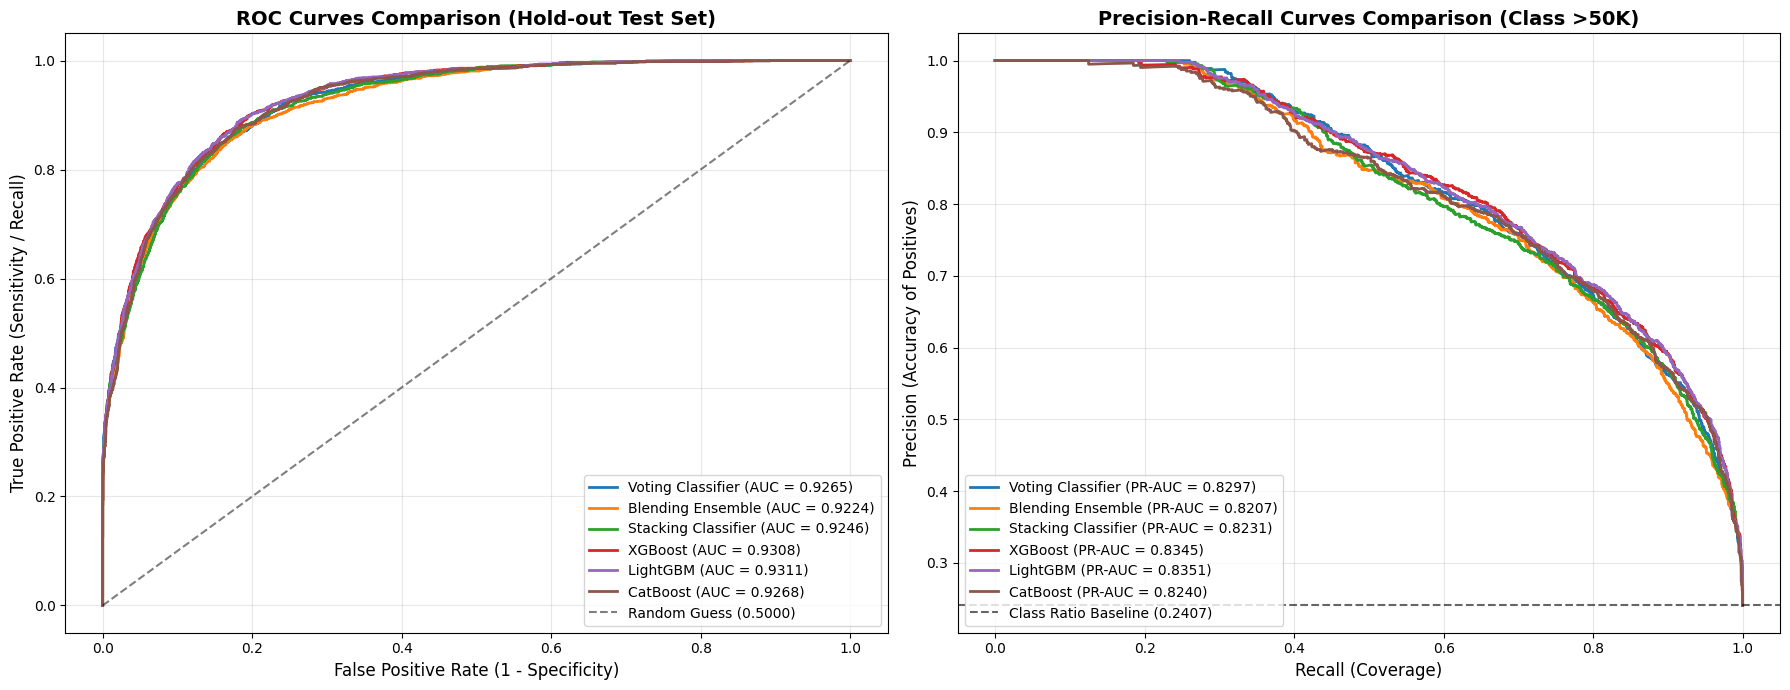

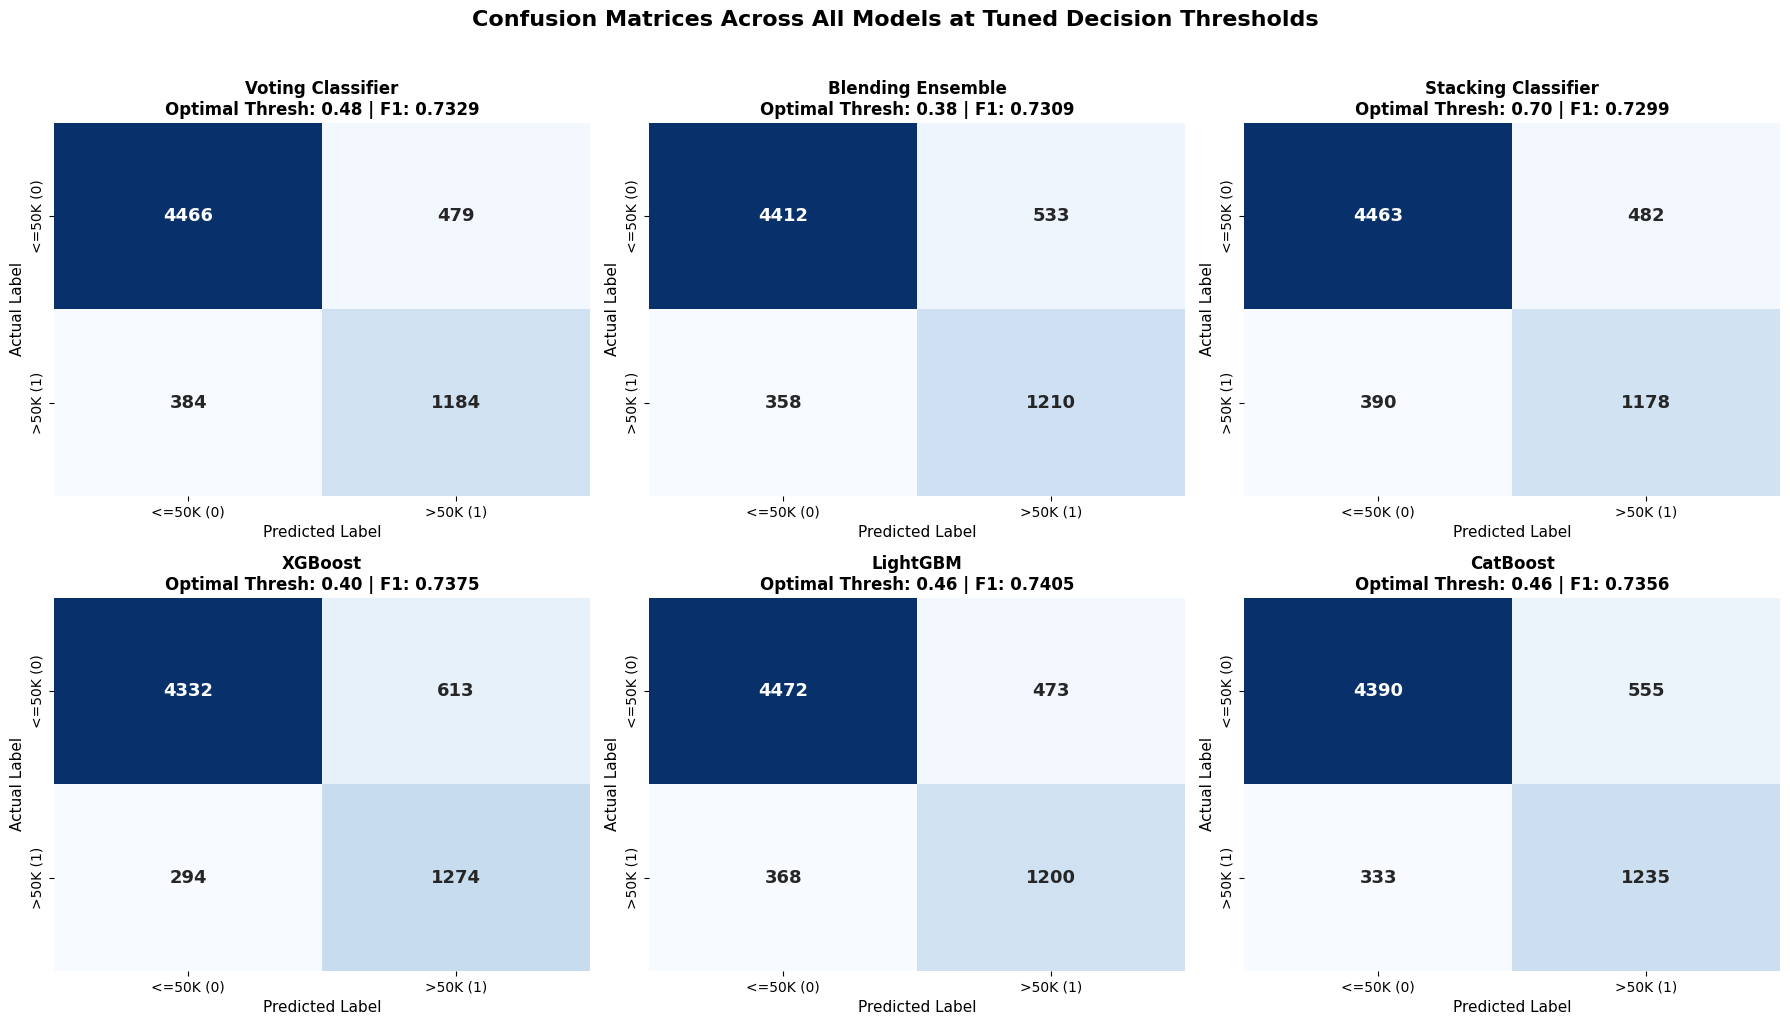

In [20]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# ==============================================================================
# 1. Prepare Test Data Formats for Different Estimators
# ==============================================================================
# Standard test set
X_test_standard = X_test.copy()

# LightGBM requires pandas 'category' dtype
X_test_lgb = X_test.copy()
for col in cat_cols:
  X_test_lgb[col] = X_test_lgb[col].astype("category")

# CatBoost requires string dtype for categorical variables
X_test_cb = X_test.copy()
for col in cat_cols:
  X_test_cb[col] = X_test_cb[col].astype(str)

# Map model names to their respective test inputs and models from fitted_models
MODELS_EVAL = {
    "Voting Classifier": (fitted_models["Voting"], X_test_standard),
    "Blending Ensemble": (fitted_models["Blending"], X_test_standard),
    "Stacking Classifier": (fitted_models["Stacking"], X_test_standard),
    "XGBoost": (fitted_models["XGBoost"], X_test_standard),
    "LightGBM": (fitted_models["LightGBM"], X_test_lgb),
    "CatBoost": (fitted_models["CatBoost"], X_test_cb),
}

# ==============================================================================
# 2. Optimal Threshold Tuning & Metric Extraction
# ==============================================================================
threshold_range = np.arange(0.10, 0.90, 0.02)
eval_summary = []
curves_data = {}
optimal_predictions = {}

print("=" * 80)
print("EVALUATING ALL 6 MODELS ON THE UNTOUCHED HOLD-OUT TEST SET (X_test)")
print("=" * 80)

for model_name, (model, current_X_test) in MODELS_EVAL.items():
  # Measure raw inference latency across test set
  t_start = time.time()
  y_probs = model.predict_proba(current_X_test)[:, 1]
  inference_duration_ms = (
      (time.time() - t_start) / len(current_X_test)
  ) * 1000

  # Search for the optimal decision threshold that maximizes F1-Score on Class 1 (>50K)
  best_thresh = 0.50
  best_f1 = 0.0

  for t in threshold_range:
    y_pred_temp = (y_probs >= t).astype(int)
    score = f1_score(y_test, y_pred_temp, zero_division=0)
    if score > best_f1:
      best_f1 = score
      best_thresh = t

  # Predictions at default (0.50) vs optimal threshold
  y_pred_default = (y_probs >= 0.50).astype(int)
  y_pred_optimal = (y_probs >= best_thresh).astype(int)
  optimal_predictions[model_name] = (y_probs, y_pred_optimal, best_thresh)

  # Compute standard discriminative metrics
  f1_default = f1_score(y_test, y_pred_default, zero_division=0)
  acc = accuracy_score(y_test, y_pred_optimal)
  rec = recall_score(y_test, y_pred_optimal)
  prec = precision_score(y_test, y_pred_optimal, zero_division=0)
  roc_auc = roc_auc_score(y_test, y_probs)
  pr_auc = average_precision_score(y_test, y_probs)

  # Confusion matrix components at optimal threshold
  cm = confusion_matrix(y_test, y_pred_optimal)
  tn, fp, fn, tp = cm.ravel()

  eval_summary.append({
      "Model": model_name,
      "F1-Score (Default 0.50)": round(f1_default, 4),
      "Optimal Threshold": round(best_thresh, 2),
      "F1-Score (Optimal)": round(best_f1, 4),
      "Precision (>50K)": round(prec, 4),
      "Recall (>50K)": round(rec, 4),
      "Accuracy": round(acc, 4),
      "PR-AUC": round(pr_auc, 4),
      "ROC-AUC": round(roc_auc, 4),
      "True Positives (TP)": tp,
      "False Positives (FP)": fp,
      "False Negatives (FN)": fn,
      "Inference Latency (ms/sample)": round(inference_duration_ms, 4),
  })

  # Store coordinates for diagnostic curves
  fpr, tpr, _ = roc_curve(y_test, y_probs)
  p_curve, r_curve, _ = precision_recall_curve(y_test, y_probs)
  curves_data[model_name] = {
      "roc": (fpr, tpr, roc_auc),
      "pr": (r_curve, p_curve, pr_auc),
  }

  print(f"\nModel: {model_name}")
  print(f"  --> Default F1 (0.50) : {f1_default:.4f}")
  print(
      f"  --> Optimal Threshold : {best_thresh:.2f} | Tuned F1-Score :"
      f" {best_f1:.4f} (Recall: {rec:.4f}, Precision: {prec:.4f})"
  )
  print(
      f"  --> ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f} | Latency :"
      f" {inference_duration_ms:.4f} ms/sample"
  )

# Convert summary into a clean dataframe
eval_df = pd.DataFrame(eval_summary).set_index("Model")
print("\n" + "=" * 80)
print("TEST EVALUATION AND THRESHOLD TUNING COMPLETE")
print("=" * 80)

# ==============================================================================
# 3. Comparative Diagnostics Curves (ROC & Precision-Recall)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- Plot A: ROC Curves ---
for name, data in curves_data.items():
  fpr, tpr, auc_val = data["roc"]
  axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (0.5000)")
axes[0].set_title(
    "ROC Curves Comparison (Hold-out Test Set)", fontsize=14, fontweight="bold"
)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, alpha=0.3)

# --- Plot B: Precision-Recall Curves ---
baseline_pos_rate = y_test.sum() / len(y_test)

for name, data in curves_data.items():
  r_curve, p_curve, pr_auc_val = data["pr"]
  axes[1].plot(
      r_curve, p_curve, lw=2, label=f"{name} (PR-AUC = {pr_auc_val:.4f})"
  )

axes[1].axhline(
    y=baseline_pos_rate,
    color="k",
    linestyle="--",
    alpha=0.6,
    label=f"Class Ratio Baseline ({baseline_pos_rate:.4f})",
)
axes[1].set_title(
    "Precision-Recall Curves Comparison (Class >50K)",
    fontsize=14,
    fontweight="bold",
)
axes[1].set_xlabel("Recall (Coverage)", fontsize=12)
axes[1].set_ylabel("Precision (Accuracy of Positives)", fontsize=12)
axes[1].legend(loc="lower left", frameon=True)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==============================================================================
# 4. Confusion Matrices at Optimal Decision Thresholds (2x3 Grid)
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
class_labels = ["<=50K (0)", ">50K (1)"]

for idx, (model_name, (model, current_X_test)) in enumerate(
    MODELS_EVAL.items()
):
  y_probs, y_pred_opt, opt_thresh = optimal_predictions[model_name]
  cm = confusion_matrix(y_test, y_pred_opt)

  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      cbar=False,
      ax=axes[idx],
      xticklabels=class_labels,
      yticklabels=class_labels,
      annot_kws={"size": 13, "weight": "bold"},
  )

  f1_val = eval_df.loc[model_name, "F1-Score (Optimal)"]
  axes[idx].set_title(
      f"{model_name}\nOptimal Thresh: {opt_thresh:.2f} | F1: {f1_val:.4f}",
      fontsize=12,
      fontweight="bold",
  )
  axes[idx].set_xlabel("Predicted Label", fontsize=11)
  axes[idx].set_ylabel("Actual Label", fontsize=11)

plt.suptitle(
    "Confusion Matrices Across All Models at Tuned Decision Thresholds",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

                                 UNIFIED MODEL COMPARISON LEADERBOARD


,Architecture Track,F1-Score (Default 0.50),Optimal Threshold,F1-Score (Optimal),Precision (>50K),Recall (>50K),Accuracy,PR-AUC,ROC-AUC,True Positives (TP),False Positives (FP),False Negatives (FN),Inference Latency (ms/sample)
Model,,,,,,,,,,,,,
LightGBM,Track B (Boosting),0.7334,0.46,0.7405,0.7173,0.7653,0.8709,0.8351,0.9311,"1,200",473,368,0.0341
XGBoost,Track B (Boosting),0.7361,0.40,0.7375,0.6751,0.8125,0.8607,0.8345,0.9308,"1,274",613,294,0.0121
CatBoost,Track B (Boosting),0.7326,0.46,0.7356,0.6899,0.7876,0.8637,0.8240,0.9268,"1,235",555,333,0.0125
Voting Classifier,Track A (Ensemble),0.7314,0.48,0.7329,0.7120,0.7551,0.8675,0.8297,0.9265,"1,184",479,384,3.1956
Blending Ensemble,Track A (Ensemble),0.7252,0.38,0.7309,0.6942,0.7717,0.8632,0.8207,0.9224,"1,210",533,358,1.7036
Stacking Classifier,Track A (Ensemble),0.7139,0.70,0.7299,0.7096,0.7513,0.8661,0.8231,0.9246,"1,178",482,390,1.8565



Calculating Test Permutation Importance for Champion Model (LightGBM)...


/tmp/ipykernel_1411/3748498688.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1411/3748498688.py:121: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


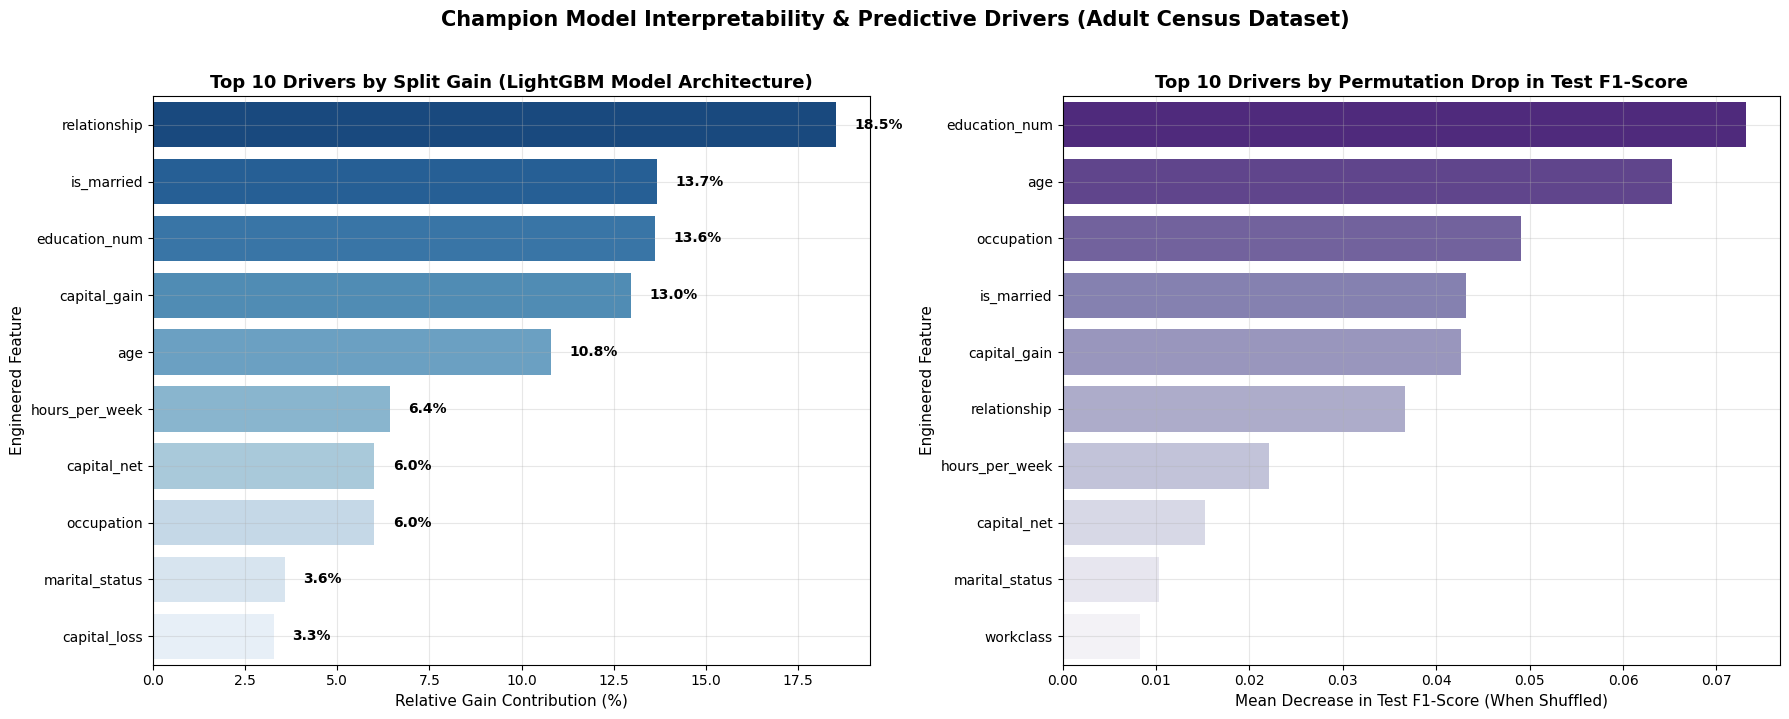


Top 5 Core Income Predictors by Permutation Impact on Test Data:
  education_num        --> Drop in F1: 0.0731 (+/- 0.0047)
  age                  --> Drop in F1: 0.0652 (+/- 0.0035)
  occupation           --> Drop in F1: 0.0491 (+/- 0.0055)
  is_married           --> Drop in F1: 0.0432 (+/- 0.0043)
  capital_gain         --> Drop in F1: 0.0427 (+/- 0.0046)


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# ==============================================================================
# 1. Unified Leaderboard Construction and Dark-Mode Friendly Formatting
# ==============================================================================
leaderboard_df = eval_df.sort_values(by="F1-Score (Optimal)", ascending=False).copy()

# Add architectural family / track label for deep comparison
model_tracks = {
    'LightGBM': 'Track B (Boosting)',
    'XGBoost': 'Track B (Boosting)',
    'CatBoost': 'Track B (Boosting)',
    'Voting Classifier': 'Track A (Ensemble)',
    'Blending Ensemble': 'Track A (Ensemble)',
    'Stacking Classifier': 'Track A (Ensemble)'
}
leaderboard_df.insert(0, 'Architecture Track', leaderboard_df.index.map(model_tracks))

print("=" * 115)
print("                                 UNIFIED MODEL COMPARISON LEADERBOARD")
print("=" * 115)

# Styling functions ensuring high contrast (readable text on dark or light backgrounds)
def highlight_best(s):
    is_max = s == s.max()
    return ['background-color: #2e7d32; color: #ffffff; font-weight: bold;' if v else '' for v in is_max]

def highlight_min_metric(s):
    is_min = s == s.min()
    return ['background-color: #6a1b9a; color: #ffffff; font-weight: bold;' if v else '' for v in is_min]

# Format numerical columns cleanly with high-contrast text styling
styled_leaderboard = (
    leaderboard_df.style.format({
        'F1-Score (Default 0.50)': '{:.4f}',
        'Optimal Threshold': '{:.2f}',
        'F1-Score (Optimal)': '{:.4f}',
        'Precision (>50K)': '{:.4f}',
        'Recall (>50K)': '{:.4f}',
        'Accuracy': '{:.4f}',
        'PR-AUC': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'Inference Latency (ms/sample)': '{:.4f}',
        'True Positives (TP)': '{:,}',
        'False Positives (FP)': '{:,}',
        'False Negatives (FN)': '{:,}'
    })
    .apply(highlight_best, subset=['F1-Score (Optimal)', 'ROC-AUC', 'PR-AUC', 'Precision (>50K)', 'Accuracy'])
    .apply(highlight_min_metric, subset=['Inference Latency (ms/sample)', 'False Positives (FP)'])
)

display(styled_leaderboard)

# ==============================================================================
# 2. Champion Model Interpretability: Feature Importance (Gain)
# ==============================================================================
champion_lgb = fitted_models['LightGBM']

# Extract native split Gain importance from LightGBM
gain_importance = champion_lgb.booster_.feature_importance(importance_type='gain')
feature_names = champion_lgb.booster_.feature_name()

gain_df = pd.DataFrame({
    'Feature': feature_names,
    'Gain_Importance': gain_importance
}).sort_values(by='Gain_Importance', ascending=False)

# Normalize gain to percentages
gain_df['Gain_Percentage'] = (gain_df['Gain_Importance'] / gain_df['Gain_Importance'].sum()) * 100

# ==============================================================================
# 3. Permutation Feature Importance on Hold-out Test Set
# ==============================================================================
print("\nCalculating Test Permutation Importance for Champion Model (LightGBM)...")

perm_result = permutation_importance(
    champion_lgb,
    X_test_lgb,
    y_test,
    scoring='f1',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test_lgb.columns,
    'Perm_Importance_Mean': perm_result.importances_mean,
    'Perm_Importance_Std': perm_result.importances_std
}).sort_values(by='Perm_Importance_Mean', ascending=False)

# ==============================================================================
# 4. Visualizing Feature Attribution & Decision Drivers
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot A: Native Gain Importance (Training Splits)
sns.barplot(
    data=gain_df.head(10),
    x='Gain_Percentage',
    y='Feature',
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title("Top 10 Drivers by Split Gain (LightGBM Model Architecture)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Relative Gain Contribution (%)", fontsize=11)
axes[0].set_ylabel("Engineered Feature", fontsize=11)
axes[0].grid(True, alpha=0.3)

# Annotate percentages on bars
for p in axes[0].patches:
    val = p.get_width()
    axes[0].annotate(f"{val:.1f}%", (val + 0.5, p.get_y() + p.get_height() / 2),
                     va='center', fontsize=10, weight='bold')

# Plot B: Test Set Permutation Importance (F1 Degradation)
sns.barplot(
    data=perm_df.head(10),
    x='Perm_Importance_Mean',
    y='Feature',
    palette='Purples_r',
    ax=axes[1]
)
axes[1].set_title("Top 10 Drivers by Permutation Drop in Test F1-Score", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Mean Decrease in Test F1-Score (When Shuffled)", fontsize=11)
axes[1].set_ylabel("Engineered Feature", fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.suptitle("Champion Model Interpretability & Predictive Drivers (Adult Census Dataset)",
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print Top Influential Predictors
print("\nTop 5 Core Income Predictors by Permutation Impact on Test Data:")
for i, row in perm_df.head(5).iterrows():
    print(f"  {row['Feature']:<20} --> Drop in F1: {row['Perm_Importance_Mean']:.4f} (+/- {row['Perm_Importance_Std']:.4f})")

# Final Model Benchmark and Interpretability Analysis

---

### 1. Final Model Performance on the Hold-out Test Set

All six tuned models were evaluated on the 20% hold-out test set (`X_test`, `y_test`). Decision thresholds were evaluated over the range [0.10, 0.90] to maximize the F1-Score for the positive class (`>50K`).

| Architecture | Track | F1 (0.50) | Optimal Threshold | Tuned F1-Score | Precision | Recall | ROC-AUC | PR-AUC | Latency (ms/sample) |
|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | Track B (Boosting) | 0.7334 | 0.46 | 0.7405 | 0.7173 | 0.7653 | 0.9311 | 0.8351 | 0.0341 |
| XGBoost | Track B (Boosting) | 0.7361 | 0.40 | 0.7375 | 0.6751 | 0.8125 | 0.9308 | 0.8345 | 0.0121 |
| CatBoost | Track B (Boosting) | 0.7326 | 0.46 | 0.7356 | 0.6899 | 0.7876 | 0.9268 | 0.8240 | 0.0125 |
| Voting Classifier | Track A (Ensemble) | 0.7314 | 0.48 | 0.7329 | 0.7120 | 0.7551 | 0.9265 | 0.8297 | 3.1956 |
| Blending Ensemble | Track A (Ensemble) | 0.7252 | 0.38 | 0.7309 | 0.6942 | 0.7717 | 0.9224 | 0.8207 | 1.7036 |
| Stacking Classifier | Track A (Ensemble) | 0.7139 | 0.70 | 0.7299 | 0.7096 | 0.7513 | 0.9246 | 0.8231 | 1.8565 |

---

### 2. Model Comparison and Key Findings

#### A. LightGBM Performance

LightGBM achieved the highest tuned F1-Score among the six models, with a value of 0.7405. It also recorded the highest ROC-AUC (0.9311) and PR-AUC (0.8351).

It produced 473 false positives, compared with 613 for XGBoost and 555 for CatBoost. Its precision was 71.73%, and its recall was 76.53%.

The measured inference latency was approximately 0.0341 ms per sample. Although XGBoost and CatBoost had lower latency in this benchmark, LightGBM achieved the highest tuned F1-Score.

#### B. Decision Threshold Optimization

Each model was evaluated using the default threshold of 0.50 and its selected threshold.

LightGBM's F1-Score increased from 0.7334 to 0.7405 after changing the threshold to 0.46. The other models were also evaluated at their respective selected thresholds.

Threshold adjustment changes the balance between precision and recall without requiring the model to be retrained. The selected threshold depends on the evaluation metric and the relative importance of false positives and false negatives.

#### C. Comparison with Ensemble Models

The Voting, Blending, and Stacking classifiers did not outperform LightGBM in tuned F1-Score.

Their measured inference latencies ranged from approximately 1.70 to 3.20 ms per sample, compared with 0.0341 ms for LightGBM.

Based on these results, LightGBM provided the highest tuned F1-Score among the evaluated models, while the ensemble models introduced additional inference time without improving this metric.

---

### 3. Feature Importance and Model Interpretability

#### A. Permutation Importance on the Test Set

Permutation importance was calculated using five random shuffles of each feature in `X_test`. The reported values represent the change in F1-Score after shuffling a feature.

1. **`education_num`** — ΔF1 = -0.0731 ± 0.0047

   This feature had the largest measured impact on model performance. Its permutation reduced the F1-Score from 0.7405 to approximately 0.6674.

2. **`age`** — ΔF1 = -0.0652 ± 0.0035

   Age was the second most important feature according to permutation importance.

3. **`occupation`** — ΔF1 = -0.0491 ± 0.0055

   Occupation contributed to the model's predictions of income level.

4. **`is_married`** — ΔF1 = -0.0432 ± 0.0043

   This engineered binary feature represented marital status using two categories.

5. **`capital_gain`** — ΔF1 = -0.0427 ± 0.0046

   Capital gain was another important predictor of income level.

#### B. Training Gain and Test Permutation Importance

Training feature gain and test-set permutation importance measure different aspects of feature importance.

- **Training Gain:** The tree-based model assigned 18.5% of its reported gain to `relationship` and 13.7% to `is_married`.
- **Test Permutation Importance:** `education_num` and `age` caused the largest reductions in F1-Score when their values were shuffled.
- **Feature Engineering:** The engineered `is_married` feature had a reported gain of 13.7%, compared with 3.6% for `marital_status`.

These results show that a feature's contribution to tree construction does not necessarily match its impact on test-set predictions. The two measures provide complementary information about how the model uses the available features.

# Executive Summary and Engineering Conclusion

---

### 1. Project Overview

This project developed a machine learning system to predict income levels (`>50K` vs. `<=50K`) using the Adult Census dataset. The workflow included separate preprocessing pipelines, Optuna hyperparameter optimization, and comparisons between individual classifiers and ensemble models.

The experiments addressed the class imbalance in the dataset, where approximately 24% of samples belong to the positive class, without using synthetic oversampling.

---

### 2. Best Performing Model: LightGBM

LightGBM achieved the best overall results among the evaluated models on the test set.

- **F1-Score:** 0.7405
- **Precision:** 0.7173
- **Recall:** 0.7653
- **ROC-AUC:** 0.9311
- **PR-AUC:** 0.8351
- **False Positives:** 473

LightGBM produced fewer false positives than XGBoost (613) and CatBoost (555).

Its average inference time was 0.034 ms per sample, making it a suitable option for applications requiring low prediction latency.

---

### 3. Comparison with Ensemble Models

Soft Voting, Blending, and Stacking were evaluated to determine whether combining multiple classifiers could improve predictive performance.

None of the ensemble models outperformed LightGBM or XGBoost in terms of F1-Score.

| Model | F1-Score | Inference Time (ms/sample) |
|---|---:|---:|
| LightGBM | 0.7405 | 0.034 |
| XGBoost | 0.7375 | — |
| Soft Voting | 0.7329 | 3.196 |
| Stacking | — | 1.857 |
| Blending | — | 1.704 |

The ensemble models also required more inference time because predictions involved multiple estimators or an additional model.

Based on these results, LightGBM provides the best balance between predictive performance and inference speed among the evaluated approaches.

---

### 4. Model Optimization and Feature Analysis

#### A. Decision Threshold

The default classification threshold of 0.50 was evaluated alongside alternative thresholds. A threshold of 0.46 was selected for LightGBM, increasing the F1-Score by 0.71% without retraining the model.

This adjustment changes how predicted probabilities are converted into class labels and can affect the balance between precision and recall.

#### B. Class Weighting

Optuna selected the following class-weighting configurations:

- LightGBM: `scale_pos_weight = 1.2610`
- XGBoost: `scale_pos_weight = 1.3026`
- CatBoost: `auto_class_weights = SqrtBalanced`

These settings were selected during hyperparameter optimization rather than applying the inverse class-frequency ratio directly.

#### C. Feature Importance

Permutation importance was used to evaluate the effect of individual features on model performance.

- **`education_num`** was the most important feature, with an F1-Score decrease of 0.0731 after permutation.
- **`age`** ranked next, with an F1-Score decrease of 0.0652.
- **`is_married`** ranked fourth, with an F1-Score decrease of 0.0432.

The `is_married` feature was created by consolidating marital-status categories into a binary indicator. During training, this feature was also reported to contribute a 13.7% gain.

These results indicate that education level, age, and occupation are important features for the model's predictions.

---

### 5. Deployment Considerations

1. **Model Pipeline:** Save the trained LightGBM model together with the preprocessing steps and categorical feature handling required during inference.

2. **Decision Threshold:** Apply the selected threshold of 0.46 when converting predicted probabilities into income classifications.

3. **Monitoring:** Monitor changes in the distributions of `education_num`, `age`, and `occupation` to identify potential data drift that could affect model performance.

4. **Performance Evaluation:** Reassess precision, recall, F1-Score, and PR-AUC on new labeled data to determine whether the model or its decision threshold requires updating.